# 03 · Extracción de Jugadas y Construcción del Dataset (Paso 4B)

Notebook para VS Code conectado a Kaggle. Consume los segmentos validados (`metadata/segmented_matches.json`) y las cajas calibradas (`metadata/ui_layouts.json`), detecta candidatos temporales ($t_{\text{drop}}$), identifica la carta jugada en $t_{\text{drop}} - 0.8\text{ s}$, localiza el despliegue en la arena y ensambla muestras de 4 fotogramas ($-6\text{ s}, -4\text{ s}, -2\text{ s}, t_{\text{actual}}$) con su acción en lenguaje natural.

**Invariantes clave incorporadas:**
- **Prevención de filtración (Data Leakage):** $t_{\text{actual}}$ se toma entre $t_{\text{drop}} - 0.8\text{ s}$ y $t_{\text{drop}} - 0.5\text{ s}$.
- **Geometría par del mapa ($18 \times 32$ casillas):** El mapa tiene 18 casillas de izquierda a derecha (número par: columnas 0–8 a la izquierda y 9–17 a la derecha de la línea central $x = 0.5$). Como ninguna carta puede desplegarse literalmente en el centro exacto, las zonas centrales y traseras se desambiguan siempre en **centro izquierda / centro derecha** y **detrás de la torre del rey (izquierda / derecha)**, guardando además la casilla `tile_xy` y la zona preliminar.
- **Catálogo de cartas:** Incluye cartas normales y versiones evolucionadas (`normal`, `evolved`) según la especificación.
- **Persistencia dual:** Revisión y exportación local atómica, con soporte para la Fase 4 de sincronización a Cloudflare R2 (`metadata/actions/<video_id>.jsonl` y `samples/`).

## 0. Dependencias y configuración de las entradas
Usar secretos en Kaggle (`R2_ENDPOINT`, `R2_ACCESS_KEY`, `R2_SECRET_KEY`, `R2_BUCKET`, `CDN_URL`). La instalación es opcional si ya tienes las dependencias.

In [ ]:
# Ejecutar SOLO si faltan dependencias; después reiniciar kernel si se solicita.
# %pip install opencv-python-headless numpy pandas matplotlib requests boto3 ipywidgets

In [99]:
import os, json, re, hashlib
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

ROOT = Path('/kaggle/working/action_pilot') if Path('/kaggle').exists() else Path('data/action_pilot')
ROOT.mkdir(parents=True, exist_ok=True)

def get_config(key, default=None):
    try:
        from kaggle_secrets import UserSecretsClient
        value = UserSecretsClient().get_secret(key)
        if value:
            return value
    except Exception:
        pass
    return os.getenv(key, default)

# Entradas locales opcionales: evita R2 si ya descargaste los manifiestos.
SEGMENTS_FILE = None  # '/kaggle/input/.../segmented_matches.json'
LAYOUTS_FILE = None   # '/kaggle/input/.../ui_layouts.json'
LOCAL_VIDEO = None    # '/kaggle/input/.../<video_id>.mp4'; debe corresponder a VIDEO_ID
VIDEO_ID = '4Tt7nuuy-Bg'       # None = primer video con partidas y calibración; o indicar un ID concreto.
MATCH_POSITION = 0    # Posición en la lista de matches, desde cero; no es match_index.
SCAN_FPS = 10.0       # 0.1 s; puede aumentarse para combos rápidos.
MAX_SCAN_SECONDS = None  # None = partida completa; un valor limita SOLO el diagnóstico.
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')

## 1. Leer manifiestos y elegir video/partida
Se conectan los manifiestos de segmentación (`metadata/segmented_matches.json`) y calibración espacial (`metadata/ui_layouts.json`). `MATCH_POSITION` es la posición en la lista (desde 0), mientras que el `match_index` original se conserva en la salida.

In [100]:
def get_s3_client():
    import boto3
    from botocore.config import Config
    values = {k: get_config(k) for k in ['R2_ENDPOINT', 'R2_ACCESS_KEY', 'R2_SECRET_KEY']}
    missing = [name for name, value in values.items() if not value or not value.strip()]
    if missing:
        raise RuntimeError(
            'No se pudo leer la configuración de R2: ' + ', '.join(missing) + '. '
            'En Kaggle, añade y habilita estos secretos en Add-ons → Secrets '
            'o define SEGMENTS_FILE y LAYOUTS_FILE con rutas locales.'
        )
    return boto3.client(
        's3',
        endpoint_url=values['R2_ENDPOINT'],
        aws_access_key_id=values['R2_ACCESS_KEY'],
        aws_secret_access_key=values['R2_SECRET_KEY'],
        config=Config(signature_version='s3v4', retries={'max_attempts': 3}),
    )

def load_manifest(local_file, key):
    if local_file:
        return json.loads(Path(local_file).read_text(encoding='utf-8'))
    client = get_s3_client()
    response = client.get_object(Bucket=R2_BUCKET, Key=key)
    try:
        return json.loads(response['Body'].read().decode('utf-8'))
    finally:
        response['Body'].close()

segments = load_manifest(SEGMENTS_FILE, 'metadata/segmented_matches.json')
layouts = load_manifest(LAYOUTS_FILE, 'metadata/ui_layouts.json')
videos = segments['videos']
ui_layouts = layouts['layouts']
choices = pd.DataFrame([
    {'video_id': vid, 'title': info.get('title', ''), 'partidas': len(info.get('matches', []))}
    for vid, info in videos.items() if vid in ui_layouts and info.get('matches')
])
display(choices)

,video_id,title,partidas
0,4Tt7nuuy-Bg,✨👀Partida de #clashroyale sin comentarios #Cla...,1
1,4YR1phwfrJU,✨👀Partida de #clashroyale sin comentarios #Cla...,1
2,4zwIliMVXV8,✨👀Partida de #clashroyale sin comentarios #Cla...,1
3,8Lls9S-ylSM,🥇Partida CLASH ROYALE sin comentar *BATALLA ÉP...,1
4,90HtKYg1jQE,✨👀Partida de #clashroyale sin comentarios #Cla...,1
5,IZrTA60YB7I,🏆3000+ 2.6 Hog top ladder,9
6,KcLv14GDAns,Partida de Clash Royale Arena 21 sin comentarios,1
7,LQdXz0DvY1c,✨👀Partida de #clashroyale sin comentarios #Cla...,1
8,QnFw3kiwOqo,✨👀Partida de #clashroyale sin comentarios #Cla...,1
9,Qy18H5V-nbE,✨👀Partida de #clashroyale sin comentarios #Cla...,1


In [101]:
if VIDEO_ID is None:
    VIDEO_ID = next((vid for vid, info in videos.items()
                     if vid in ui_layouts and info.get('matches')), None)
    if VIDEO_ID is None:
        raise RuntimeError('No hay videos con partidas y calibración en ambos manifiestos.')
    print(f'Video seleccionado automáticamente: {VIDEO_ID}')
if not re.fullmatch(r'[A-Za-z0-9_-]+', VIDEO_ID):
    raise ValueError('VIDEO_ID no válido.')
if VIDEO_ID not in videos or VIDEO_ID not in ui_layouts:
    raise ValueError('El video debe existir en ambos manifiestos.')
match_list = videos[VIDEO_ID]['matches']
display(pd.DataFrame(match_list))
if not 0 <= MATCH_POSITION < len(match_list):
    raise ValueError('MATCH_POSITION fuera de rango.')
match = match_list[MATCH_POSITION]
layout = ui_layouts[VIDEO_ID]
START, END = float(match['start_sec']), float(match['end_sec'])
if END <= START:
    raise ValueError('Intervalo de partida inválido.')
if not 10 <= SCAN_FPS <= 60:
    raise ValueError('Usa entre 10 y 60 muestras por segundo para este detector.')
RUN_DIR = ROOT / VIDEO_ID / f'partida_{MATCH_POSITION:02d}'
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f'Video {VIDEO_ID} | posición {MATCH_POSITION} | match_id {match.get("match_id")}')
print(f'Intervalo absoluto del MP4: {START:.2f}–{END:.2f} s; duración {END-START:.2f} s')

,match_id,match_index,start_sec,end_sec,duration_sec,start_clock,end_clock,in_overtime,youtube_url
0,4Tt7nuuy-Bg_p01,1,114,293,179,2:57,0:00,False,https://youtu.be/4Tt7nuuy-Bg?t=114


Video 4Tt7nuuy-Bg | posición 0 | match_id 4Tt7nuuy-Bg_p01
Intervalo absoluto del MP4: 114.00–293.00 s; duración 179.00 s


## 2. Descargar el video desde el CDN y validar sus dimensiones
El MP4 se descarga desde `https://cdn-cr.eddux.dev/videos/<video_id>.mp4`. El análisis se limita al intervalo `start_sec`–`end_sec` de la partida.

In [102]:
def validate_video(path):
    cap = cv2.VideoCapture(str(path))
    try:
        ok, frame = cap.read()
        if not cap.isOpened() or not ok or frame is None:
            raise RuntimeError('El MP4 no se puede decodificar.')
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not np.isfinite(fps) or fps <= 0 or count <= 0:
            raise RuntimeError('FPS o duración del MP4 inválidos.')
        return fps, count, frame.shape[1], frame.shape[0]
    finally:
        cap.release()

def fetch_video(vid):
    target = ROOT / f'{vid}.mp4'
    if target.exists():
        validate_video(target)
        return target
    partial = target.with_suffix('.mp4.part')
    try:
        with requests.get(f'{CDN_BASE}/videos/{vid}.mp4', stream=True, timeout=(15, 120)) as response:
            response.raise_for_status()
            expected = response.headers.get('Content-Length')
            with partial.open('wb') as out:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        out.write(chunk)
            if expected and not response.headers.get('Content-Encoding') and partial.stat().st_size != int(expected):
                raise RuntimeError('Descarga incompleta.')
        validate_video(partial)
        partial.replace(target)
    except Exception:
        partial.unlink(missing_ok=True)
        raise
    return target

VIDEO_PATH = Path(LOCAL_VIDEO) if LOCAL_VIDEO else fetch_video(VIDEO_ID)
SOURCE_FPS, FRAME_COUNT, WIDTH, HEIGHT = validate_video(VIDEO_PATH)
if SOURCE_FPS < SCAN_FPS:
    raise ValueError('El muestreo solicitado supera los FPS del video.')
if END > FRAME_COUNT / SOURCE_FPS + 1 / SOURCE_FPS:
    raise ValueError('El intervalo del manifiesto supera la duración del video; verificar el MP4 seleccionado.')
if list(layout['resolution']) != [WIDTH, HEIGHT]:
    raise ValueError('Resolución distinta a la calibración. No se escalan cajas silenciosamente.')

# Las cajas del notebook 02 son [x, y, ancho, alto], NO [x1, y1, x2, y2].
BOXES = layout['boxes_pixel']

def checked_box(box, shape):
    x, y, w, h = map(int, box)
    ih, iw = shape[:2]
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x+w > iw or y+h > ih:
        raise ValueError(f'Caja fuera de imagen: {box}; imagen {iw}x{ih}')
    return x, y, w, h

def crop(frame, box):
    x, y, w, h = checked_box(box, frame.shape)
    return frame[y:y+h, x:x+w]

if len(BOXES['card_slots']) != 4:
    raise ValueError('Se esperan exactamente cuatro slots.')
for box in [BOXES['arena_box'], BOXES['elixir_bar_box'], *BOXES['card_slots']]:
    checked_box(box, (HEIGHT, WIDTH))

def read_frame(t):
    if not START <= t <= END:
        raise ValueError('El fotograma solicitado queda fuera de la partida.')
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    try:
        index = min(int(round(t * SOURCE_FPS)), FRAME_COUNT-1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f'No se pudo leer el frame en {t:.3f}s')
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    finally:
        cap.release()

print(f'MP4 {WIDTH}×{HEIGHT}, {SOURCE_FPS:.3f} fps; se conserva localmente para revisión.')

MP4 590×1280, 59.720 fps; se conserva localmente para revisión.


### Vista previa de las cajas originales
Las cajas del manifiesto son `[x, y, ancho, alto]`. Revisa arena, cuatro slots y caja completa de elixir.

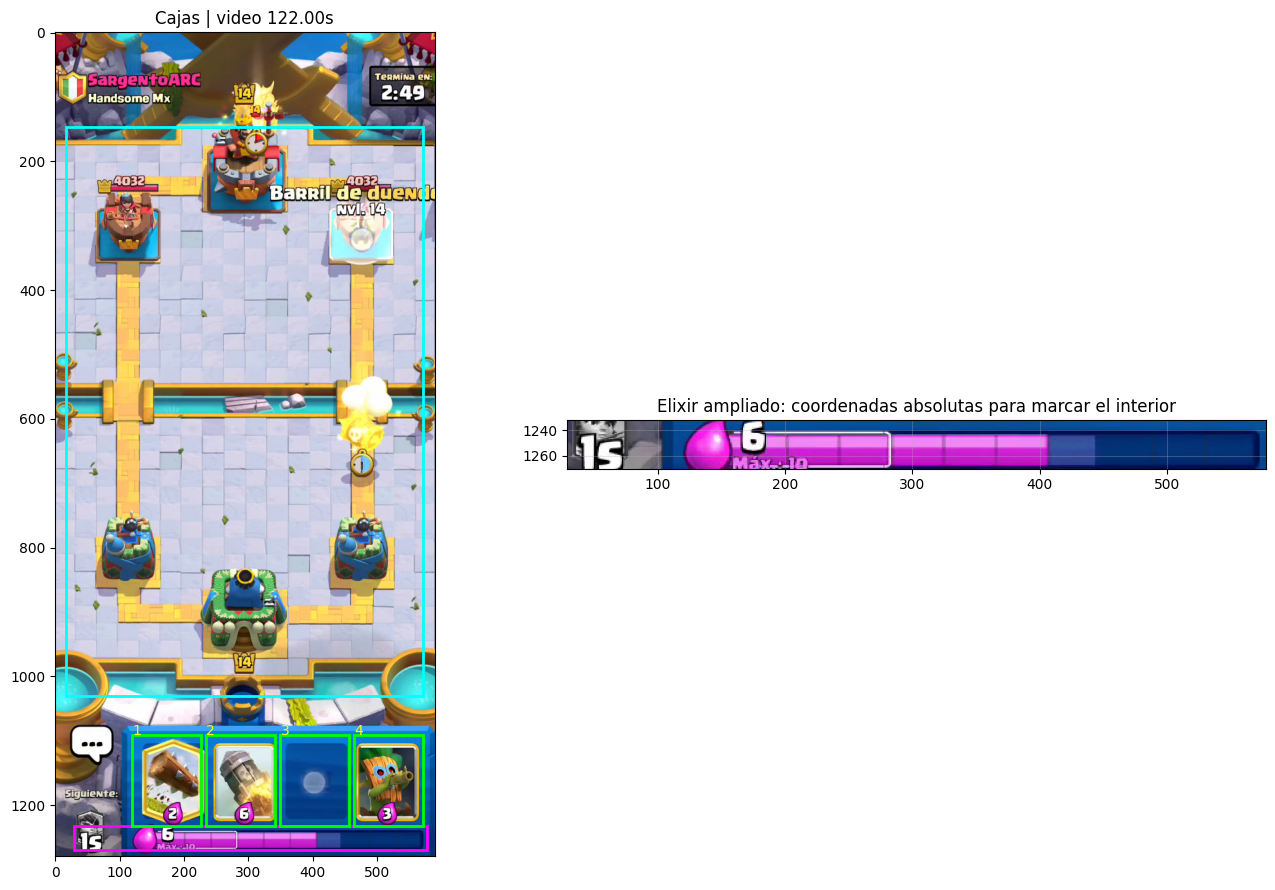

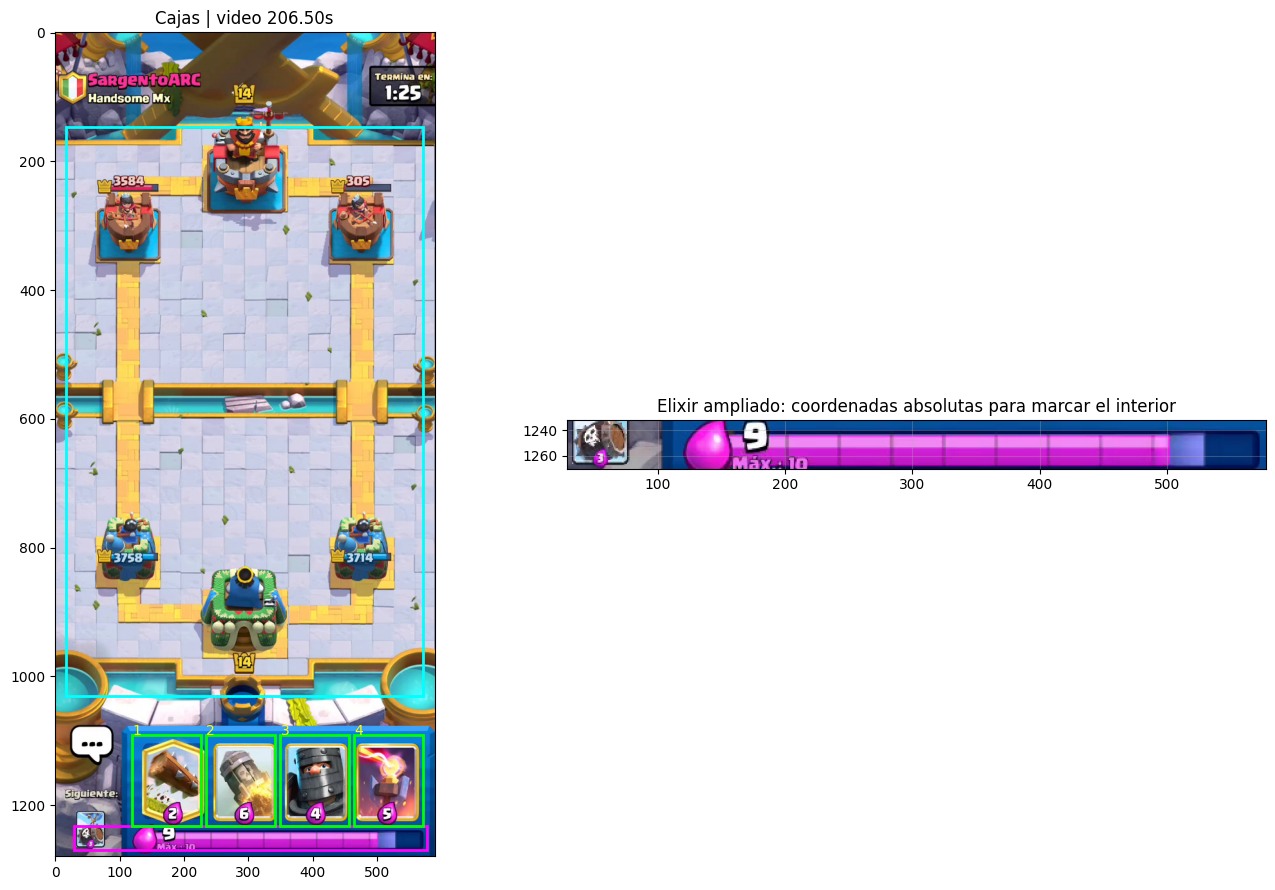

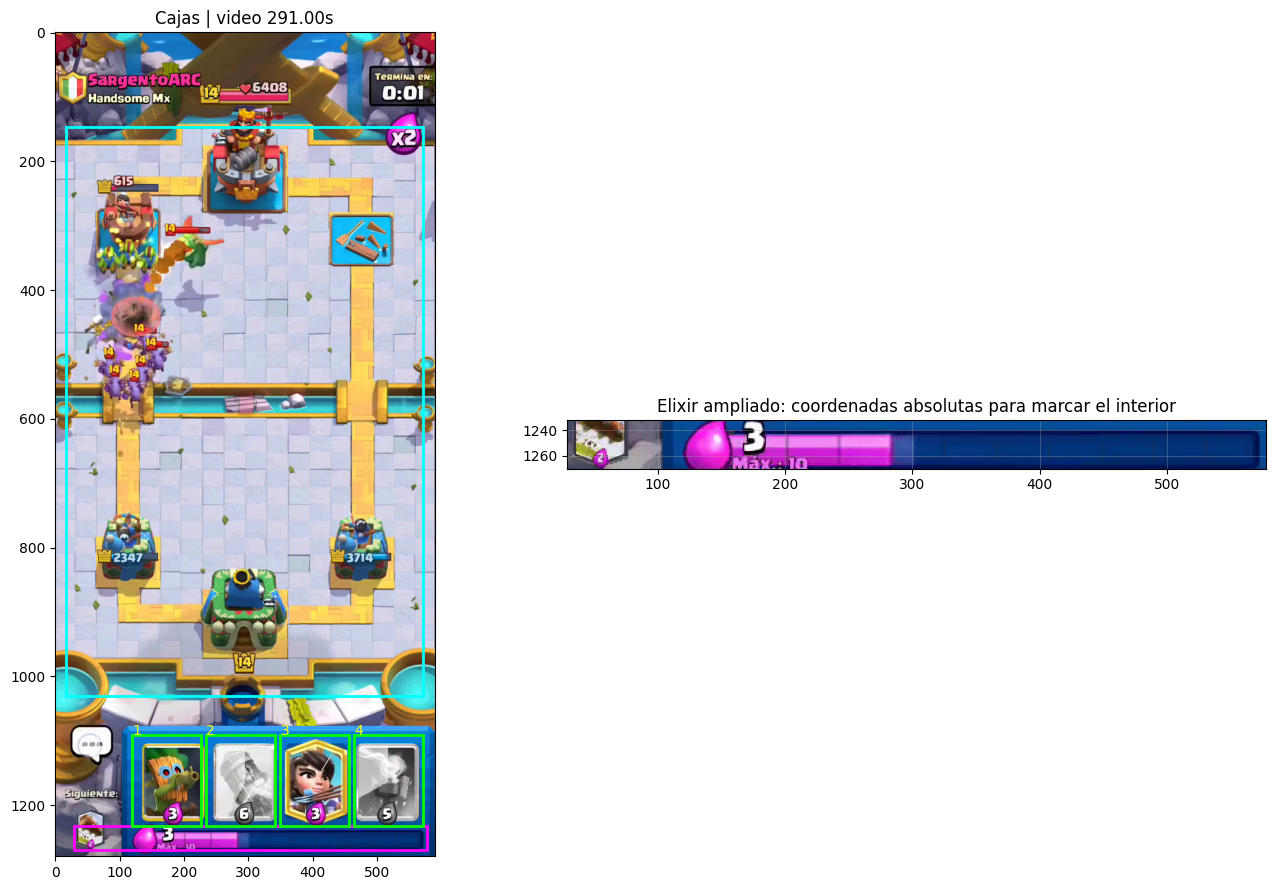

In [103]:
def show_layout(t):
    frame = read_frame(t)
    fig, axes = plt.subplots(1, 2, figsize=(14, 9))
    axes[0].imshow(frame)
    colors = {'arena_box': 'cyan', 'elixir_bar_box': 'magenta'}
    for key, color in colors.items():
        x,y,w,h = BOXES[key]
        axes[0].add_patch(plt.Rectangle((x,y), w,h, fill=False, edgecolor=color, linewidth=2))
    for i, box in enumerate(BOXES['card_slots'], 1):
        x,y,w,h = box
        axes[0].add_patch(plt.Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=2))
        axes[0].text(x,y,str(i),color='yellow')
    axes[0].set_title(f'Cajas | video {t:.2f}s')
    x,y,w,h = BOXES['elixir_bar_box']
    axes[1].imshow(crop(frame, [x,y,w,h]), extent=(x,x+w,y+h,y))
    axes[1].set_title('Elixir ampliado: coordenadas absolutas para marcar el interior')
    axes[1].grid(alpha=.3)
    plt.tight_layout()
    plt.show()

for t in np.linspace(START+min(8., (END-START)/4), END-min(2., (END-START)/4), 3):
    show_layout(float(t))

## Funciones de los 4 Sub-sistemas del Pipeline
Ejecutar estas celdas en orden:
1. **Sub-sistema 1:** Detector Temporal de Eventos ($t_{\text{drop}}$, caída de elixir $\Delta E$, rotación de slot y filtro de menú de chat).
2. **Sub-sistema 2:** Identificador de Carta Jugada (captura en $t_{\text{drop}} - 0.8\text{ s}$ y validación cruzada de coste y rotación).
3. **Sub-sistema 3:** Localizador Espacial en la Arena (ventana $[t_{\text{drop}} - 0.2\text{ s}, t_{\text{drop}} + 0.4\text{ s}]$, cuadrícula par $18 \times 32$ sin centro exacto, desambiguación izquierda/derecha).
4. **Sub-sistema 4:** Muestreo de `'esperar'` (balance 15%–20%) y Ensamblador de Muestras VLM.

In [104]:
"""Extracción asistida de jugadas y construcción del dataset VLM."""
from __future__ import annotations
import csv
import hashlib
import json
import math
import os
import re
import shutil
import tempfile
import time
from dataclasses import asdict, dataclass
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PIPELINE_VERSION = '3.5-even-grid-18x32-r2-1.0'

In [105]:
def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    allow_nan=False).encode()).hexdigest()[:20]

In [106]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

In [107]:
def atomic_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

In [108]:
def checked_box(box, shape):
    if len(box) != 4 or any(not np.isfinite(v) for v in box):
        raise ValueError('Caja XYWH inválida.')
    x, y, w, h = map(int, box)
    ih, iw = shape[:2]
    if min(x, y) < 0 or min(w, h) <= 0 or x+w > iw or y+h > ih:
        raise ValueError(f'Caja XYWH {box} fuera de imagen {iw}x{ih}.')
    return x, y, w, h

In [109]:
def crop(frame, box):
    x, y, w, h = checked_box(box, frame.shape)
    return frame[y:y+h, x:x+w]

#### Parámetros de lectura, muestreo y cuadrícula par ($18 \times 32$)

In [110]:
@dataclass(frozen=True)
class Parameters:
    scan_fps: float = 10.
    hsv_low: tuple = (125, 65, 60)
    hsv_high: tuple = (179, 255, 255)
    column_min: float = .35
    primary_drop: float = 1.5
    small_drop: float = .55
    descent_step: float = .12
    max_drop_window: float = .5
    slot_change: float = .10
    slot_margin: float = .025
    chat_blue: float = .50
    decision_offset: float = .7
    canonical_size: tuple = (640, 1280)  # ancho, alto; conserva proporciones con letterbox
    grid_cols: int = 18  # Número PAR de casillas de izquierda a derecha (0..8 izq, 9..17 der)
    grid_rows: int = 32  # 32 casillas de arriba a abajo
    river_y: float = .50
    bridge_depth: float = .28
    king_depth: float = .85
    center_left: float = .3333   # 6 / 18 casillas (columnas 6..8 = centro izquierda)
    center_right: float = .6667  # 12 / 18 casillas (columnas 9..11 = centro derecha)
    card_min_score: float = .72
    card_margin: float = .06
    max_duration_sec: float | None = None

    def validate(self):
        if not 10 <= self.scan_fps <= 60:
            raise ValueError('Usar 10–60 muestras/s para detectar combos.')
        if not .5 <= self.decision_offset <= .8:
            raise ValueError('El frame de decisión debe preceder t_drop entre 0.5 y 0.8 s.')
        if not 0 < self.small_drop <= self.primary_drop or self.descent_step <= 0:
            raise ValueError('Umbrales de caída inválidos.')
        if not 0 < self.max_drop_window <= .5:
            raise ValueError('Ventana de caída: como máximo 0.5 s.')
        if self.grid_cols <= 0 or self.grid_cols % 2 != 0 or self.grid_rows <= 0:
            raise ValueError('La cuadrícula de Clash Royale debe tener un número PAR de columnas (ej. 18x32).')
        if not 0 < self.river_y < 1 or not 0 < self.bridge_depth < self.king_depth < 1:
            raise ValueError('Divisiones de zona inválidas.')
        if not 0 < self.center_left < 0.5 < self.center_right < 1:
            raise ValueError('Divisiones horizontales inválidas; deben rodear el eje central x=0.5.')
        if any(int(v) != v or v <= 0 for v in self.canonical_size):
            raise ValueError('Tamaño canónico inválido.')
        if self.max_duration_sec is not None and self.max_duration_sec <= 0:
            raise ValueError('La duración de diagnóstico debe ser positiva.')

#### Lectura del video por tiempo real

In [111]:
class Video:
    """Tiempos absolutos del MP4. END es exclusivo; se informa tiempo real del frame."""
    def __init__(self, path, start, end):
        self.path = Path(path)
        self.start, self.end = float(start), float(end)
        cap = cv2.VideoCapture(str(path))
        try:
            ok, frame = cap.read()
            self.fps = float(cap.get(cv2.CAP_PROP_FPS))
            self.count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if not ok or not np.isfinite(self.fps) or self.fps <= 0 or self.count <= 0:
                raise ValueError('No se puede decodificar el MP4 o sus metadatos son inválidos.')
            self.height, self.width = frame.shape[:2]
        finally:
            cap.release()
        if not 0 <= self.start < self.end <= self.count/self.fps + 1e-6:
            raise ValueError('Segmento fuera de la duración del video.')
        self.source_hash = file_sha256(path)

    def frame(self, timestamp):
        if not np.isfinite(timestamp) or not self.start <= timestamp < self.end:
            raise ValueError(f'Frame {timestamp} fuera de [{self.start}, {self.end}).')
        cap = cv2.VideoCapture(str(self.path))
        try:
            if not cap.set(cv2.CAP_PROP_POS_MSEC, timestamp*1000):
                raise RuntimeError('El decodificador no admite búsqueda temporal.')
            ok, bgr = cap.read()
            actual = float(cap.get(cv2.CAP_PROP_POS_MSEC))/1000
            if not ok or not np.isfinite(actual) or (actual == 0 and timestamp > 2/self.fps):
                raise RuntimeError('El backend no informa tiempos de presentación. No estimar tiempos finales solo con FPS.')
            if not self.start <= actual < self.end or abs(actual-timestamp) > 2/self.fps:
                raise RuntimeError('El frame leído no coincide con la partida/tiempo solicitado.')
            return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), actual
        finally:
            cap.release()

    def sequence(self, a, b, fps):
        """Decodificación secuencial con PTS del backend; compatible con tiempos no uniformes."""
        if not self.start <= a < b <= self.end or not 0 < fps <= self.fps:
            raise ValueError('Intervalo/frecuencia de lectura inválidos.')
        next_t = a
        cap = cv2.VideoCapture(str(self.path))
        try:
            cap.set(cv2.CAP_PROP_POS_MSEC, a*1000)
            previous = -np.inf
            while True:
                ok, frame = cap.read()
                if not ok:
                    if previous < b-2/self.fps:
                        raise RuntimeError('Lectura interrumpida; no aceptar un análisis parcial como completo.')
                    break
                t = float(cap.get(cv2.CAP_PROP_POS_MSEC))/1000
                if not np.isfinite(t) or t <= previous:
                    raise RuntimeError('Timestamps de presentación ausentes/no crecientes; revisar el backend de video.')
                previous = t
                if t >= b: break
                if t < a: continue
                if t+1e-8 >= next_t:
                    yield t, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    next_t = max(next_t + 1/fps, t + .5/fps)
        finally:
            cap.release()

#### Lectura del elixir y detección de destellos

In [112]:
def elixir_observation(rgb, params):
    """Lectura magenta + control de destello. No convierte blanco en elixir lleno."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, np.array(params.hsv_low), np.array(params.hsv_high)) > 0
    columns = mask.mean(axis=0) >= params.column_min
    pieces = np.array_split(columns, min(100, len(columns)))
    raw = float(10*np.mean([part.mean() >= .5 for part in pieces]))
    white = ((hsv[:,:,1] < 65) & (hsv[:,:,2] > 215)).mean(axis=0) >= .5
    white[:max(1,round(len(white)*.045))] = False
    changes = np.diff(np.r_[False,white,False].astype(int))
    widths = np.flatnonzero(changes == -1)-np.flatnonzero(changes == 1)
    longest = int(widths.max()) if len(widths) else 0
    flash = longest >= max(3, int(np.ceil(len(white)*.06)))
    return {'raw':raw, 'value':float('nan') if flash else raw,
            'flash':bool(flash), 'white_fraction':float(white.mean()), 'mask':mask}

In [113]:
def elixir_signal(rgb, params):
    reading = elixir_observation(rgb, params)
    return reading['value'], reading['mask']

#### Tratamiento temporal de lecturas dudosas

In [114]:
def stabilize_elixir(times, values, max_gap=.65):
    """Retira valles breves con rebote incompatible y salva huecos cortos."""
    t=np.asarray(times,float);v=np.asarray(values,float).copy()
    original=v.copy()
    for i in range(1,len(v)-1):
        if not np.isfinite(original[i-1:i+1]).all():continue
        if original[i-1]-original[i] < .8:continue
        for j in range(i+1,min(len(v),i+5)):
            if t[j]-t[i-1] > max_gap:break
            if not np.isfinite(original[j]):continue
            if original[j]-original[i] > max(.8, 1.5*(t[j]-t[i])):
                if np.nanmax(original[i:j]) < original[j]-.5:v[i:j]=np.nan
                break
    uncertain=~np.isfinite(v)
    filled=np.zeros(len(v),bool)
    i=0
    while i<len(v):
        if np.isfinite(v[i]):i+=1;continue
        j=i
        while j<len(v) and not np.isfinite(v[j]):j+=1
        if i>0 and j<len(v) and t[j]-t[i-1]<=max_gap:
            v[i:j]=v[i-1];filled[i:j]=True
        i=j
    return v,uncertain,filled

#### Compensación del sombreado de la arena y geometría de casillas pares ($18 \times 32$)

In [115]:
def arena_residual(before,after,river_y=.5):
    """Compensa cambio de color afín robusto por mitad; conserva cambios locales."""
    a=before.astype(np.float32);b=after.astype(np.float32)
    prediction=a.copy();h,w=a.shape[:2];cut=round(h*river_y)
    for lo,hi in [(0,cut),(cut,h)]:
        if hi<=lo:continue
        for channel in range(3):
            x=a[lo:hi:4,::4,channel].ravel();y=b[lo:hi:4,::4,channel].ravel()
            keep=np.ones(len(x),bool);gain=1.;bias=0.
            for _ in range(3):
                if keep.sum()<10:break
                if np.std(x[keep])<3:
                    gain=1.;bias=float(np.median(y[keep]-x[keep]))
                else:
                    matrix=np.column_stack([x[keep],np.ones(keep.sum())])
                    gain,bias=np.linalg.lstsq(matrix,y[keep],rcond=None)[0]
                    gain=float(np.clip(gain,.5,2.));bias=float(np.clip(bias,-110,110))
                residual=np.abs(y-(gain*x+bias))
                keep=residual<=max(3.,float(np.percentile(residual,70)))
            prediction[lo:hi,:,channel]=gain*a[lo:hi,:,channel]+bias
    residual=np.abs(b-np.clip(prediction,0,255)).astype(np.uint8)
    gray=cv2.cvtColor(residual,cv2.COLOR_RGB2GRAY)
    gray=cv2.GaussianBlur(gray,(5,5),0)
    return gray,float((gray>25).mean())

In [116]:
def descriptor(rgb):
    h, w = rgb.shape[:2]
    center = rgb[int(.18*h):max(int(.8*h), int(.18*h)+1),
                 int(.1*w):max(int(.9*w), int(.1*w)+1)]
    return cv2.resize(center, (32, 40), interpolation=cv2.INTER_AREA).astype(np.float32)/255

In [117]:
def aligned_distance(a, b):
    """Compara ilustraciones tolerando elevación vertical por selección."""
    scores = []
    h = a.shape[0]
    for shift in range(-8, 9, 2):
        if shift >= 0:
            aa, bb = a[:h-shift or h], b[shift:]
        else:
            aa, bb = a[-shift:], b[:h+shift]
        scores.append(np.abs(aa-bb).mean())
    return float(min(scores))

In [118]:
def blue_fraction(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    return float((cv2.inRange(hsv, np.array([90,70,35]), np.array([125,255,255])) > 0).mean())

In [119]:
def white_selection(rgb):
    h = max(1, int(rgb.shape[0]*.3))
    area = rgb[:h]
    return float(((area.min(axis=2) > 195) & (np.ptp(area.astype(float), axis=2) < 45)).mean())

In [120]:
def arena_tile(coord, p):
    """Proyecta (x, y) en [0, 1]^2 a la cuadrícula par de Clash Royale (18x32).

    Como hay un número PAR de casillas de izquierda a derecha (18 columnas: 0..8
    a la izquierda y 9..17 a la derecha de la línea divisoria central x=0.5),
    ninguna carta puede colocarse en un centro literal; siempre cae en la mitad
    izquierda ('left') o en la mitad derecha ('right').
    """
    x, y = map(float, coord)
    if not 0 <= x <= 1 or not 0 <= y <= 1:
        raise ValueError('Coordenadas de arena fuera de [0,1].')
    col = min(p.grid_cols - 1, max(0, int(math.floor(x * p.grid_cols))))
    row = min(p.grid_rows - 1, max(0, int(math.floor(y * p.grid_rows))))
    half = p.grid_cols // 2
    # Si x == 0.5 exacto en flotante, se resuelve por la casilla cuantizada.
    side = 'left' if (x < 0.5 or col < half) else 'right'
    return [int(col), int(row)], side

def canonical_zone_from_specific(zone_label):
    """Mapea la zona desambiguada (izq/der) a las 6 zonas preliminares del spec."""
    if zone_label is None:
        return None
    if zone_label.startswith('Centro '):
        return 'Centro del campo propio'
    if zone_label.startswith('Detrás de la torre del rey'):
        return 'Detrás de la torre del rey'
    return zone_label

def zone_for(coord, p):
    """Clasifica la coordenada respetando el número par de casillas horizontales.

    Las posiciones centrales y detrás del rey nunca quedan en un centro ambiguo:
    se desambiguan como 'Centro izquierda del campo propio' / 'Centro derecha del campo propio'
    y 'Detrás de la torre del rey (izquierda)' / 'Detrás de la torre del rey (derecha)'.
    """
    x, y = map(float, coord)
    tile_xy, side = arena_tile(coord, p)
    if y < p.river_y:
        return None  # hechizos/minero/etc. en campo rival: requieren zona explícita
    depth = (y - p.river_y) / (1 - p.river_y)
    if depth >= p.king_depth:
        return 'Detrás de la torre del rey (izquierda)' if side == 'left' else 'Detrás de la torre del rey (derecha)'
    if depth < p.bridge_depth:
        return 'Detrás del puente izquierdo' if side == 'left' else 'Detrás del puente derecho'
    if p.center_left <= x <= p.center_right:
        return 'Centro izquierda del campo propio' if side == 'left' else 'Centro derecha del campo propio'
    return 'Frente a la torre izquierda' if side == 'left' else 'Frente a la torre derecha'

def format_target_text(card_name, placement_zone, variant='normal'):
    """Construye la oración natural para el VLM a partir de la carta y la zona."""
    name = f'{card_name} (evolucionada)' if variant == 'evolved' else str(card_name)
    zone = str(placement_zone).strip().rstrip('.')
    lower = zone.lower()
    if lower.startswith('centro izquierda'):
        phrase = 'en el centro izquierda del campo propio'
    elif lower.startswith('centro derecha'):
        phrase = 'en el centro derecha del campo propio'
    elif lower.startswith('centro '):
        phrase = 'en el ' + zone[0].lower() + zone[1:]
    elif lower.startswith('frente a '):
        phrase = 'frente a ' + zone[9:]
    elif lower.startswith('detrás '):
        phrase = 'detrás ' + zone[7:]
    else:
        phrase = zone[0].lower() + zone[1:]
    return f'Juega {name} {phrase}.'

In [121]:
def letterbox(rgb, size):
    width, height = map(int, size)
    h, w = rgb.shape[:2]
    scale = min(width/w, height/h)
    rw, rh = max(1, round(w*scale)), max(1, round(h*scale))
    canvas = np.zeros((height, width, 3), dtype=np.uint8)
    x, y = (width-rw)//2, (height-rh)//2
    canvas[y:y+rh, x:x+rw] = cv2.resize(rgb, (rw,rh), interpolation=cv2.INTER_AREA)
    return canvas, {'scale':scale, 'offset_xy':[x,y], 'source_size':[w,h], 'canvas_size':[width,height]}

#### Referencias locales y compatibilidad

In [122]:
class CardBank:
    """Banco extensible: varias referencias por carta/variante ('normal' o 'evolved')."""
    def __init__(self, root):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.index_path = self.root/'templates.json'
        self.entries = json.loads(self.index_path.read_text()) if self.index_path.exists() else []
        self._cache = {}

    @property
    def fingerprint(self):
        return digest([dict(e, bytes_sha=file_sha256(self.root/e['image'])) for e in self.entries])

    def add(self, image, name, cost, variant, kind, provenance):
        if not str(name).strip() or variant not in {'normal','evolved','unknown'}:
            raise ValueError('Nombre y variante válidos obligatorios.')
        if kind not in {'troop','building','spell','unknown'} or int(cost) != cost or not 0 <= cost <= 10:
            raise ValueError('Tipo o coste inválido. Costes especiales deben revisarse manualmente.')
        if not str(provenance).strip():
            raise ValueError('Registrar procedencia de la plantilla.')
        key = digest({'name':name.strip(),'variant':variant,'kind':kind,'cost':int(cost),
                      'pixels':hashlib.sha256(image.tobytes()).hexdigest()})
        path = self.root/f'{key}.png'
        if not cv2.imwrite(str(path), cv2.cvtColor(image, cv2.COLOR_RGB2BGR)):
            raise OSError('No se pudo escribir plantilla.')
        entry = {'key':key,'name_es':name.strip(),'cost':int(cost),'variant':variant,
                 'kind':kind,'image':path.name,'provenance':str(provenance)}
        self.entries = [e for e in self.entries if e['key'] != key] + [entry]
        atomic_json(self.index_path, self.entries)
        self._cache.clear()
        return entry

    def import_csv(self, path):
        frame = pd.read_csv(path, keep_default_na=False)
        required = {'name_es','cost','variant','kind','image_path','provenance'}
        if not required <= set(frame.columns):
            raise ValueError(f'El CSV necesita columnas {sorted(required)}')
        imported=[]
        for row in frame.to_dict('records'):
            image_path = Path(row['image_path'])
            if not image_path.is_absolute():
                image_path = Path(path).parent/image_path
            bgr = cv2.imread(str(image_path))
            if bgr is None:
                raise ValueError(f'No se pudo abrir referencia: {image_path.name}')
            imported.append(self.add(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB), row['name_es'],
                                     float(row['cost']),row['variant'],row['kind'],row['provenance']))
        return imported

    def rank(self, rgb, p):
        target = descriptor(rgb)
        matches=[]
        for e in self.entries:
            if e['key'] not in self._cache:
                ref = cv2.imread(str(self.root/e['image']))
                if ref is None:
                    raise ValueError('Referencia del banco ausente o ilegible.')
                self._cache[e['key']] = descriptor(cv2.cvtColor(ref,cv2.COLOR_BGR2RGB))
            ref = self._cache[e['key']]
            distance = aligned_distance(target,ref)
            a = cv2.cvtColor(target,cv2.COLOR_RGB2GRAY).ravel()
            b = cv2.cvtColor(ref,cv2.COLOR_RGB2GRAY).ravel()
            corr = float(np.corrcoef(a,b)[0,1]) if min(a.std(),b.std()) > 1e-6 else 0.
            score = .75*(1-distance) + .25*max(0.,corr)
            matches.append(dict(e,score=float(score)))
        matches.sort(key=lambda e:e['score'],reverse=True)
        identities={}
        for e in matches:
            identities.setdefault((e['name_es'],e['variant']),e)
        return sorted(identities.values(),key=lambda e:e['score'],reverse=True)

#### Configuración, cajas y visualización de la cuadrícula par ($18 \times 32$)

In [123]:
class _LayoutPipeline:
    def __init__(self, video_path, video_id, match, match_position, layout, bar_track,
                 output_root, bank_root, params=None):
        self.p = params or Parameters()
        self.p.validate()
        if not re.fullmatch(r'[A-Za-z0-9_-]+',video_id):
            raise ValueError('video_id inválido.')
        self.video_id, self.match, self.match_position = video_id, dict(match), int(match_position)
        self.video = Video(video_path, match['start_sec'],match['end_sec'])
        if self.video.fps < self.p.scan_fps:
            raise ValueError('El muestreo supera los FPS nativos.')
        if list(layout['resolution']) != [self.video.width,self.video.height]:
            raise ValueError('Resolución del video distinta de la calibración.')
        self.boxes = json.loads(json.dumps(layout['boxes_pixel']))
        if len(self.boxes['card_slots']) != 4:
            raise ValueError('Se necesitan cuatro slots.')
        for box in [self.boxes['arena_box'],self.boxes['elixir_bar_box'],*self.boxes['card_slots']]:
            checked_box(box,(self.video.height,self.video.width))
        self.bar = list(checked_box(bar_track,(self.video.height,self.video.width)))
        ex,ey,ew,eh=self.boxes['elixir_bar_box']; x,y,w,h=self.bar
        if not (ex<=x and ey<=y and x+w<=ex+ew and y+h<=ey+eh):
            raise ValueError('Interior de barra fuera de su caja general.')
        self.bank=CardBank(bank_root)
        self.config={'version':PIPELINE_VERSION,'video_id':video_id,'match':self.match,
                     'match_position':self.match_position,'video_sha256':self.video.source_hash,
                     'boxes':self.boxes,'bar':self.bar,'params':asdict(self.p)}
        self.run_id=digest(self.config)
        self.root=Path(output_root)/video_id/f'match_{self.match_position:02d}'/self.run_id
        self.root.mkdir(parents=True,exist_ok=True)
        atomic_json(self.root/'run_config.json',self.config)
        self.review_path=self.root/'review.json'
        self.reviews=json.loads(self.review_path.read_text()) if self.review_path.exists() else {}
        self.audit_path=self.root/'audited_intervals.json'
        self.audits=json.loads(self.audit_path.read_text()) if self.audit_path.exists() else []
        self.events=[]
        self.preview_tokens=set()
        self.loaded_bank_hash=self.bank.fingerprint
        self.layout_approved=False
        self.zones_approved=False
        self.signals=None
        self.hand=None
        self._scanned_identity=None

    def approve_layout(self, token):
        if token != self.run_id:
            raise ValueError('Token de layout desactualizado. Revisa el plot actual.')
        self.layout_approved=True

    def plot_layout(self, timestamp=None):
        t=timestamp if timestamp is not None else min(self.video.start+8,self.video.end-.5)
        frame,actual=self.video.frame(t)
        fig=plt.figure(figsize=(15,10))
        gs=fig.add_gridspec(3,2,width_ratios=[1,1.6],height_ratios=[3,1,1])
        ax=fig.add_subplot(gs[:,0]); ax.imshow(frame)
        for key,color in [('arena_box','cyan'),('elixir_bar_box','magenta')]:
            x,y,w,h=self.boxes[key]; ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,color=color,lw=2))
        for i,box in enumerate(self.boxes['card_slots'],1):
            x,y,w,h=box;ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,color='lime'))
            ax.text(x,y,str(i),color='yellow')
        ax.set_title(f'{self.video_id} | {actual:.3f}s')
        x,y,w,h=self.boxes['elixir_bar_box']
        ax=fig.add_subplot(gs[0,1]);ax.imshow(crop(frame,[x,y,w,h]),extent=(x,x+w,y+h,y),aspect='auto')
        bx,by,bw,bh=self.bar;ax.add_patch(plt.Rectangle((bx,by),bw,bh,fill=False,color='lime',lw=2))
        ax.set_title('Caja completa y franja interior: coordenadas absolutas')
        bar=crop(frame,self.bar);value,mask=elixir_signal(bar,self.p)
        ax=fig.add_subplot(gs[1,1]);ax.imshow(bar,aspect='auto');ax.set_title(f'Interior: estimación {value:.2f}/10')
        ax=fig.add_subplot(gs[2,1]);ax.imshow(mask,cmap='gray',aspect='auto');ax.set_title('Máscara magenta; contrastar con número del juego')
        fig.suptitle(f'REVISIÓN MANUAL DE CAJAS | token {self.run_id}')
        fig.tight_layout();return fig

    def plot_zones(self,timestamp=None):
        frame,_=self.video.frame(timestamp or min(self.video.start+8,self.video.end-.5))
        image=crop(frame,self.boxes['arena_box'])
        fig,ax=plt.subplots(figsize=(8,11));ax.imshow(image,extent=(0,1,1,0))
        # Dibujar cuadrícula 18x32 (número par de casillas horizontales)
        for col in range(1, self.p.grid_cols):
            ax.axvline(col / self.p.grid_cols, color='white', alpha=.18, lw=.7)
        for row in range(1, self.p.grid_rows):
            ax.axhline(row / self.p.grid_rows, color='white', alpha=.15, lw=.6)
        ry=self.p.river_y; near=ry+(1-ry)*self.p.bridge_depth; ky=ry+(1-ry)*self.p.king_depth
        for y in [ry,near,ky]:ax.axhline(y,color='yellow',lw=2)
        # Línea divisoria central x=0.5 entre la casilla 9 (col 8) y la casilla 10 (col 9)
        ax.plot([.5,.5],[ry,1.0],color='cyan',ls='--',lw=2,label='Divisoria par (9 izq | 9 der)')
        for x in [self.p.center_left,self.p.center_right]:ax.plot([x,x],[near,ky],color='yellow',lw=2)
        labels = [
            ((.25,(ry+near)/2),'1 · Puente izq.'),
            ((.75,(ry+near)/2),'2 · Puente der.'),
            ((.16,(near+ky)/2),'3 · Frente torre izq.'),
            ((.84,(near+ky)/2),'4 · Frente torre der.'),
            ((.415,(near+ky)/2),'5L · Centro izq.'),
            ((.585,(near+ky)/2),'5R · Centro der.'),
            ((.30,(ky+1)/2),'6L · Detrás rey (izq.)'),
            ((.70,(ky+1)/2),'6R · Detrás rey (der.)'),
        ]
        for xy,txt in labels:
            ax.text(*xy,txt,ha='center',va='center',color='white',fontsize=8.5,
                    bbox={'facecolor':'black','alpha':.7})
        ax.legend(loc='upper right')
        ax.set_title(f'Cuadrícula par {self.p.grid_cols}×{self.p.grid_rows}: sin casilla central exacta (siempre izq. o der.)')
        ax.set_xlabel('x normalizada (9 casillas izq. | 9 casillas der.)');ax.set_ylabel('y normalizada')
        fig.tight_layout();return fig

    def approve_zones(self,token):
        if token!=self.run_id:raise ValueError('Revisa las zonas de esta ejecución.')
        self.zones_approved=True

#### Escaneo de señales (Sub-sistema 1)

In [124]:
class _ScanPipeline:
    def scan(self, use_cache=True):
        if not self.layout_approved:
            raise RuntimeError('Revisar plot_layout y aprobar su token antes del escaneo.')
        cache=self.root/'scan.npz'
        stop=min(self.video.end,self.video.start+self.p.max_duration_sec) if self.p.max_duration_sec else self.video.end
        if use_cache and cache.exists():
            with np.load(cache,allow_pickle=False) as data:
                t,e,hand,blue,white,raw,flash=[data[k] for k in ['t','e','hand','blue','white','raw','flash']]
        else:
            times=[];levels=[];hands=[];blues=[];whites=[];raws=[];flashes=[]
            for t,frame in self.video.sequence(self.video.start,stop,self.p.scan_fps):
                cards=[crop(frame,b) for b in self.boxes['card_slots']]
                observation=elixir_observation(crop(frame,self.bar),self.p)
                times.append(t);levels.append(observation['value'])
                raws.append(observation['raw']);flashes.append(observation['flash'])
                hands.append(np.stack([descriptor(c) for c in cards]))
                blues.append([blue_fraction(c) for c in cards]);whites.append([white_selection(c) for c in cards])
                if len(times)%int(self.p.scan_fps*30)==0:
                    print(f'Escaneados {t-self.video.start:.0f}/{stop-self.video.start:.0f}s',flush=True)
            if len(times)<12:raise ValueError('Tramo demasiado corto.')
            t,e,hand,blue,white,raw,flash=map(np.asarray,[times,levels,hands,blues,whites,raws,flashes])
            temp=cache.with_suffix('.tmp.npz');np.savez_compressed(temp,t=t,e=e,hand=hand,blue=blue,white=white,raw=raw,flash=flash);temp.replace(cache)
        self.hand=hand
        stabilized,uncertain,filled=stabilize_elixir(t,e)
        self.signals=pd.DataFrame({'timestamp_sec':t,'elixir':stabilized,
            'elixir_raw':raw,'elixir_observed':e,'elixir_flash':flash,
            'elixir_uncertain':uncertain,'elixir_filled':filled,
            'chat':(blue>=self.p.chat_blue).all(axis=1)})
        for i in range(4):
            self.signals[f'blue_{i+1}']=blue[:,i];self.signals[f'white_{i+1}']=white[:,i]
        self._scanned_identity=self.run_id
        print(f'{len(t)} muestras. Candidatos de chat: {int(self.signals.chat.sum())}. Pendiente de revisión.')
        return self.signals

    def _assert_scanned(self):
        if self.signals is None or self._scanned_identity!=self.run_id:
            raise RuntimeError('Ejecuta scan() para esta configuración.')

    def _chat_between(self,a,b):
        self._assert_scanned()
        s=self.signals
        mask=s.timestamp_sec.between(a-1/self.p.scan_fps,b+1/self.p.scan_fps)
        return bool(s.loc[mask,'chat'].any())

#### Candidatos temporales ($t_{\text{drop}}$)

In [125]:
class _DetectionPipeline:
    def detect(self):
        self._assert_scanned()
        t=self.signals.timestamp_sec.to_numpy();e=self.signals.elixir.to_numpy();n=len(t)
        increments=np.r_[0.,e[:-1]-e[1:]]
        active=np.flatnonzero(increments>=self.p.descent_step)
        groups=[]
        for index in active:
            if (groups and index==groups[-1][-1]+1 and
                t[index]-t[groups[-1][0]]<=self.p.max_drop_window):
                groups[-1].append(int(index))
            else:groups.append([int(index)])
        events=[]
        persistent=np.zeros((n,4));step=np.zeros((n,4))
        for i in range(1,n):
            step[i]=[aligned_distance(self.hand[i-1,k],self.hand[i,k]) for k in range(4)]
        for i,x in enumerate(t):
            pre=np.searchsorted(t,x-.8,side='right')-1;post=np.searchsorted(t,x+.5)
            if pre>=0 and post<n:
                persistent[i]=[aligned_distance(self.hand[pre,k],self.hand[post,k]) for k in range(4)]
        for group in groups:
            i=group[0];j=group[-1]
            drop=float(e[max(0,i-1)]-e[j])
            if drop<self.p.small_drop:continue
            quality=self.signals.elixir_uncertain.to_numpy()
            pre=(t>=t[max(0,i-1)]-.2)&(t<=t[max(0,i-1)])&~quality
            post=(t>=t[j])&(t<=t[j]+.2)&~quality
            if pre.sum()>=2 and post.sum()>=2:
                stable_drop=float(np.median(e[pre])-np.median(e[post]))
                if stable_drop>=self.p.small_drop:drop=stable_drop
            onset=max(0,i-1)
            while onset>0 and quality[onset]:onset-=1
            affected=bool(quality[onset:j+1].any())
            strengths=persistent[i];order=np.argsort(strengths)[::-1]
            top,second=float(strengths[order[0]]),float(strengths[order[1]])
            ambiguous=top>=self.p.slot_change and top-second<self.p.slot_margin
            slot=int(order[0])+1 if top>=self.p.slot_change and not ambiguous else None
            label='revisar_destello' if affected else ('doble_señal' if slot else ('slot_ambiguo' if ambiguous else 'revisar_caida'))
            events.append(self._new_event(float(t[i]),drop,slot,label,'play_candidate',
                                         {'native_interval':[float(t[onset]),float(t[j])],
                                          'elixir_uncertain':affected,
                                          'slot_scores':strengths.tolist(),'low_cost':drop<self.p.primary_drop}))
        last=-np.inf
        for i in range(1,n):
            strength=float(step[i].max())
            if strength<self.p.slot_change or t[i]-last<.5:continue
            if any(abs(ev['timestamp_sec']-t[i])<=.5 for ev in events):continue
            last=t[i]
            events.append(self._new_event(float(t[i]),0.,int(step[i].argmax())+1,
                                         'seleccion_sin_gasto','selection_diagnostic',{}))
        manual_path=self.root/'manual_events.json'
        manual=json.loads(manual_path.read_text()) if manual_path.exists() else []
        self.events=sorted(events+manual,key=lambda ev:ev['timestamp_sec'])
        if len({ev['candidate_id'] for ev in self.events})!=len(self.events):
            raise ValueError('IDs duplicados; revisar eventos manuales.')
        self.signals['drop_step']=increments
        for k in range(4):self.signals[f'slot_{k+1}_change']=step[:,k]
        self.signals.to_csv(self.root/'signals.csv',index=False)
        atomic_json(self.root/'candidates.json',self.events)
        pd.DataFrame(self.events).to_csv(self.root/'candidates.csv',index=False)
        return self.table()

    def _new_event(self,t,drop,slot,label,event_type,extra):
        ident=digest({'run':self.run_id,'t':round(t,6),'type':event_type,'slot':slot})
        return {'candidate_id':ident,'timestamp_sec':float(t),'relative_sec':float(t-self.video.start),
                'drop_estimate':float(drop),'slot_candidate':slot,'signal':label,'event_type':event_type,
                'occluded':self._chat_between(max(self.video.start,t-.8),min(self.video.end,t+.5)),
                'review_status':'pending',**extra}

    def table(self, include_selections=False):
        rows=[]
        for event in self.events:
            if not include_selections and event['event_type']=='selection_diagnostic':continue
            row=dict(event);record=self.reviews.get(event['candidate_id'],{})
            row['review_status']=record.get('decision','pending') if self._review_current(record) else 'pending'
            rows.append(row)
        return pd.DataFrame(rows)

    def _get_event(self,event_id):
        return next(e for e in self.events if e['candidate_id']==event_id)

    def add_manual_event(self,t,slot=None,notes=''):
        if not self.video.start<=t<self.video.end:raise ValueError('Tiempo fuera de partida.')
        if slot is not None and slot not in [1,2,3,4]:raise ValueError('Slot 1–4.')
        event=self._new_event(float(t),0.,slot,'manual','manual_play',{'notes':str(notes)})
        path=self.root/'manual_events.json'
        items=json.loads(path.read_text()) if path.exists() else []
        if any(e['candidate_id']==event['candidate_id'] for e in self.events):raise ValueError('Evento duplicado.')
        items.append(event);atomic_json(path,items)
        self.events=sorted(self.events+[event],key=lambda e:e['timestamp_sec'])
        return event['candidate_id']

    def refine_time(self,event_id):
        ev=self._get_event(event_id);t=ev['timestamp_sec']
        a=max(self.video.start,t-.3);b=min(self.video.end,t+.5)
        rows=[]
        for ts,frame in self.video.sequence(a,b,self.video.fps):
            rows.append({'timestamp_sec':ts,'elixir':elixir_signal(crop(frame,self.bar),self.p)[0]})
        frame=pd.DataFrame(rows)
        frame['elixir'],frame['elixir_uncertain'],_=stabilize_elixir(frame.timestamp_sec,frame.elixir)
        frame['descent']=frame.elixir.shift()-frame.elixir
        if len(frame)>1 and frame.descent.max()>.05:
            onset=frame[frame.descent>.05].iloc[0].timestamp_sec
        else:onset=t
        return float(onset),frame

#### Referencias y lectura de cartas (Sub-sistema 2)

In [126]:
class _CardsPipeline:
    def capture_template(self,t,slot,name,cost,variant='unknown',kind='unknown'):
        if slot not in [1,2,3,4]:raise ValueError('Slot 1–4.')
        frame,actual=self.video.frame(t)
        entry=self.bank.add(crop(frame,self.boxes['card_slots'][slot-1]),name,cost,variant,kind,
                            f'{self.video_id}:frame={actual:.6f}:slot={slot}; etiqueta humana')
        self.loaded_bank_hash=self.bank.fingerprint
        self.preview_tokens.clear()
        return entry

    def identify(self,event,t=None,slot=None):
        ts=float(event['timestamp_sec'] if t is None else t)
        slot=event.get('slot_candidate') if slot is None else slot
        if slot is not None and np.isfinite(slot): slot=int(slot)
        if slot not in [1,2,3,4] or ts-.8<self.video.start:
            return {'state':'slot_o_historia_insuficiente','alternatives':[]}
        frame,actual=self.video.frame(ts-.8)
        image=crop(frame,self.boxes['card_slots'][slot-1]);ranks=self.bank.rank(image,self.p)
        if not ranks:return {'state':'banco_vacio','alternatives':[],'slot_image':image}
        first=ranks[0];margin=first['score']-ranks[1]['score'] if len(ranks)>1 else 0.
        accepted=first['score']>=self.p.card_min_score and margin>=self.p.card_margin
        difference=abs(first['cost']-float(event['drop_estimate']))
        return {'state':'propuesta' if accepted else 'ambiguo','name_es':first['name_es'],
                'cost':first['cost'],'variant':first['variant'],'kind':first['kind'],
                'score':first['score'],'margin':margin,'cost_consistent':difference<=1.,
                'reference':first['image'],'source_time':actual,'alternatives':ranks[:4], 'slot_image':image}

#### Localización en la arena y proyección a casillas pares $18 \times 32$ (Sub-sistema 3)

In [127]:
class _SpatialPipeline:
    def locate(self,t,kind='unknown'):
        if not self.video.start<=t-.2<t+.4<self.video.end:
            return {'state':'borde_partida','proposals':[]}
        before,_=self.video.frame(t-.2);after,_=self.video.frame(t+.4)
        a,b=crop(before,self.boxes['arena_box']),crop(after,self.boxes['arena_box'])
        gray,global_fraction=arena_residual(a,b,self.p.river_y)
        h,w=gray.shape
        threshold=max(22.,float(np.percentile(gray,92)))
        mask=(gray>threshold).astype(np.uint8)*255
        mask[:max(1,round(h*.04))]=0;mask[round(h*.96):]=0
        mask[:,:max(1,round(w*.025))]=0;mask[:,round(w*.975):]=0
        if kind!='spell':mask[:round(h*self.p.river_y)]=0
        if global_fraction>.45:
            return {'state':'cambio_global_no_resuelto','proposals':[],
                    'before':a,'after':b,'difference':gray,'mask':mask,
                    'global_change_fraction':global_fraction}
        mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,np.ones((3,3),np.uint8))
        count,labels,stats,centroids=cv2.connectedComponentsWithStats(mask)
        hsv=cv2.cvtColor(b,cv2.COLOR_RGB2HSV)
        hsv0=cv2.cvtColor(a,cv2.COLOR_RGB2HSV)
        bright=((hsv[:,:,1]<90)&(hsv[:,:,2]>195)) | ((hsv[:,:,0]>12)&(hsv[:,:,0]<40)&(hsv[:,:,2]>165))
        bright0=((hsv0[:,:,1]<90)&(hsv0[:,:,2]>195)) | ((hsv0[:,:,0]>12)&(hsv0[:,:,0]<40)&(hsv0[:,:,2]>165))
        newly_bright=bright & ~bright0
        proposals=[]
        for i in range(1,count):
            x,y,bw,bh,area=map(int,stats[i])
            if not max(8,h*w*.0001)<=area<=h*w*.025:continue
            if bw>w*.22 or bh>h*.18:continue
            if bh<max(3,round(h*.015)) or bw<3 or max(bw/bh,bh/bw)>4:continue
            cx,cy=centroids[i];coord=[float(cx/w),float(cy/h)]
            tile_xy, side = arena_tile(coord, self.p)
            zone_specific = zone_for(coord, self.p)
            support=labels==i
            novelty=float(newly_bright[support].mean())
            change=float(gray[support].mean()/255)
            score=change+.5*novelty
            proposals.append({
                'coord':coord,
                'tile_xy':tile_xy,
                'arena_side':side,
                'score':score,
                'area':area,
                'box':[x,y,bw,bh],
                'new_bright_fraction':novelty,
                'zone':zone_specific,
                'canonical_zone':canonical_zone_from_specific(zone_specific),
            })
        proposals.sort(key=lambda proposal:proposal['score'],reverse=True)
        decisive=bool(proposals and proposals[0]['new_bright_fraction']>=.12 and
                      (len(proposals)==1 or proposals[0]['score']-proposals[1]['score']>=.08))
        return {'state':'propuesta_espacial_por_revisar' if decisive else
                        ('posicion_ambigua' if proposals else 'sin_localizacion'),
                'auto_fill':decisive,'proposals':proposals[:5],'before':a,'after':b,
                'difference':gray,'mask':mask,'global_change_fraction':global_fraction}

    def analyse(self, event_id, t=None, slot=None):
        ev=self._get_event(event_id)
        t=float(ev['timestamp_sec'] if t is None else t)
        ident=self.identify(ev,t,slot)
        location=self.locate(t,ident.get('kind','unknown'))
        return ident,location

#### Gráficos de revisión

In [128]:
class _PlotsPipeline:
    def plot_event(self,event_id,t=None,slot=None):
        ev=self._get_event(event_id);t=float(ev['timestamp_sec'] if t is None else t)
        fig,axes=plt.subplots(3,5,figsize=(17,9),gridspec_kw={'height_ratios':[4,1.4,.6]})
        for col,offset in enumerate([-.8,-.3,0.,.3,.6]):
            ts=t+offset
            if not self.video.start<=ts<self.video.end:
                for row in range(3):axes[row,col].axis('off')
                continue
            frame,actual=self.video.frame(ts)
            axes[0,col].imshow(crop(frame,self.boxes['arena_box']));axes[0,col].set_title(f'{offset:+.1f}s | {actual:.3f}s')
            cards=[cv2.resize(crop(frame,b),(80,100)) for b in self.boxes['card_slots']]
            axes[1,col].imshow(np.concatenate(cards,axis=1));axes[1,col].set_title('1 | 2 | 3 | 4')
            bar=crop(frame,self.bar);value,_=elixir_signal(bar,self.p)
            axes[2,col].imshow(bar,aspect='auto')
            axes[2,col].set_title(f'Elixir ≈ {value:.2f}' if np.isfinite(value) else 'Destello: sin lectura fiable')
            for row in range(3):axes[row,col].axis('off')
        fig.suptitle(f'{event_id} | {ev["signal"]} | {t:.3f}s | VISTA DE REVISIÓN')
        fig.tight_layout();return fig

    def plot_analysis(self,event_id,t=None,slot=None):
        ident,loc=self.analyse(event_id,t,slot)
        fig,axes=plt.subplots(2,4,figsize=(15,9))
        for ax in axes.flat:ax.axis('off')
        if 'slot_image' in ident:
            axes[0,0].imshow(ident['slot_image']);axes[0,0].set_title(f'Slot previo: {ident.get("source_time", 0):.3f}s')
        for ax,rank in zip(axes[0,1:],ident.get('alternatives',[])[:3]):
            bgr=cv2.imread(str(self.bank.root/rank['image']))
            ax.imshow(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
            ax.set_title(f'{rank["name_es"]}\n{rank["variant"]} | score {rank["score"]:.3f}')
        if 'before' in loc:
            for ax,key in zip(axes[1,:3],['before','after','difference']):
                ax.imshow(loc[key],cmap='inferno' if key=='difference' else None);ax.set_title(key)
            ax=axes[1,3];ax.imshow(loc['after'],extent=(0,1,1,0))
            ax.axvline(0.5, color='cyan', ls='--', lw=1.2)
            for i,proposal in enumerate(loc['proposals'],1):
                x,y=proposal['coord'];ax.plot(x,y,'ro')
                ax.text(x,y,f"{i}:{proposal['tile_xy']}",color='yellow',fontsize=8)
            ax.set_title('Propuestas (línea cian = divisoria par)')
        fig.suptitle(f'Carta: {ident["state"]} | posición: {loc["state"]} | revisar coste y variante')
        fig.tight_layout();return fig

    def plot_timeline(self,a=None,b=None):
        self._assert_scanned();s=self.signals
        a=s.timestamp_sec.iloc[0] if a is None else a;b=s.timestamp_sec.iloc[-1] if b is None else b
        sub=s[s.timestamp_sec.between(a,b)]
        if sub.empty:raise ValueError('Ventana vacía.')
        fig,axes=plt.subplots(4,1,figsize=(16,10),sharex=True)
        if 'elixir_raw' in sub:
            axes[0].plot(sub.timestamp_sec,sub.elixir_raw,color='gray',alpha=.5,label='Magenta sin control')
            bad=sub.elixir_uncertain
            axes[0].scatter(sub.loc[bad,'timestamp_sec'],sub.loc[bad,'elixir_raw'],color='red',s=12,label='Lectura dudosa')
            axes[0].legend()
        axes[0].plot(sub.timestamp_sec,sub.elixir);axes[0].set_ylim(-.2,10.2);axes[0].set_ylabel('Elixir ≈')
        axes[1].plot(sub.timestamp_sec,sub.get('drop_step',pd.Series(0,index=sub.index)))
        axes[1].axhline(self.p.small_drop,color='orange',ls='--');axes[1].set_ylabel('Caída / paso')
        for k in range(1,5):axes[2].plot(sub.timestamp_sec,sub.get(f'slot_{k}_change',pd.Series(0,index=sub.index)),label=f'Slot {k}')
        axes[2].legend();axes[2].set_ylabel('Cambio alineado')
        axes[3].plot(sub.timestamp_sec,sub[[f'blue_{k}' for k in range(1,5)]].min(axis=1))
        axes[3].axhline(self.p.chat_blue,color='blue',ls='--');axes[3].set_ylabel('Azul mínimo')
        for ev in self.events:
            if a<=ev['timestamp_sec']<=b and ev['event_type']!='selection_diagnostic':
                axes[0].axvline(ev['timestamp_sec'],color='green' if ev['signal']=='doble_señal' else 'orange',alpha=.6)
        for ax in axes:
            ax.grid(alpha=.2)
            ax.fill_between(sub.timestamp_sec,0,1,where=sub.chat.to_numpy(),transform=ax.get_xaxis_transform(),color='blue',alpha=.1)
        axes[-1].set_xlabel('Segundos absolutos del MP4');fig.tight_layout();return fig

    def plot_audit(self,a,b,step=.5):
        if not self.video.start<=a<b<=self.video.end or step<=0:raise ValueError('Ventana inválida.')
        times=np.arange(a,b,step)
        if len(times)>24:raise ValueError('Usa páginas de 24 imágenes como máximo.')
        fig,axes=plt.subplots(math.ceil(len(times)/4),4,figsize=(14,math.ceil(len(times)/4)*5),squeeze=False)
        for ax,t in zip(axes.flat,times):
            frame,actual=self.video.frame(float(t));ax.imshow(frame);ax.set_title(f'{actual:.3f}s');ax.axis('off')
        for ax in list(axes.flat)[len(times):]:ax.axis('off')
        fig.tight_layout();return fig

#### Preparación de las cuatro entradas (Sub-sistema 4)

In [129]:
class _SamplesPipeline:
    def _review_context(self):
        return digest({'run':self.run_id,'bank':self.bank.fingerprint,'version':PIPELINE_VERSION})

    def _review_current(self,record):
        return bool(record) and record.get('context')==self._review_context()

    def _payload(self,event_id,t,slot,name,cost,variant,kind,coord,zone_text='',notes=''):
        ev=self._get_event(event_id)
        if not np.isfinite(t) or not self.video.start<=t<self.video.end:raise ValueError('Tiempo inválido.')
        if ev['event_type']=='wait_candidate':
            return {'candidate_id':event_id,'action_type':'wait','timestamp_sec':float(t),
                    'hand_slot':None,'card_name':None,'elixir_cost':None,'variant':None,
                    'kind':None,'placement_coord':None,'tile_xy':None,'arena_side':None,
                    'placement_zone':None,'canonical_zone':None,'notes':str(notes)}
        if slot not in [1,2,3,4]:raise ValueError('Seleccionar slot 1–4.')
        if name is None or not str(name).strip() or str(name).strip().lower() in {'unknown','desconocida','pendiente'}:
            raise ValueError('Identificar la carta antes de aprobar.')
        if cost is None or not np.isfinite(cost) or int(cost)!=cost or not 0<=cost<=10:
            raise ValueError('Confirmar el coste entero 0–10.')
        if variant not in {'normal','evolved'}:raise ValueError('Confirmar variante normal o evolved.')
        if kind not in {'troop','building','spell'}:raise ValueError('Confirmar tipo de carta.')
        if coord is None or len(coord)!=2 or not all(np.isfinite(c) for c in coord):
            raise ValueError('Confirmar coordenada normalizada [x,y].')
        coord=[round(float(c), 4) for c in coord]
        tile_xy, side = arena_tile(coord, self.p)
        zone = zone_for(coord, self.p)
        if zone is None:
            if not str(zone_text).strip():
                raise ValueError('Fuera del campo propio: escribir zona explícita (indicando izquierda/derecha).')
            zone = str(zone_text).strip()
            canonical_zone = zone
        else:
            canonical_zone = canonical_zone_from_specific(zone)
        return {'candidate_id':event_id,'action_type':'play','timestamp_sec':float(t),'hand_slot':int(slot),
                'card_name':str(name).strip(),'elixir_cost':int(cost),'variant':variant,'kind':kind,
                'placement_coord':coord,'tile_xy':tile_xy,'arena_side':side,
                'placement_zone':zone,'canonical_zone':canonical_zone,'notes':str(notes)}

    def _input_frames(self,payload):
        t=payload['timestamp_sec']
        current=t-self.p.decision_offset if payload['action_type']=='play' else t
        frames=[];times=[]
        for back in [6.,4.,2.,0.]:
            image,actual=self.video.frame(current-back)
            if payload['action_type']=='play' and back==0. and not .5-1e-8<=t-actual<=.8+1e-8:
                raise ValueError('El frame real no cumple separación 0.5–0.8s respecto a t_drop.')
            if self._chat_between(actual,actual):raise ValueError('Posible chat en una imagen de entrada; revisar antes de exportar.')
            frames.append(image);times.append(float(actual))
        if not all(a<b for a,b in zip(times,times[1:])):raise ValueError('Frames repetidos o desordenados.')
        return frames,times

    def _sample_token(self,payload,frames,times):
        return digest({'context':self._review_context(),'payload':payload,'actual_frames':times,
                       'image_pixels':[hashlib.sha256(f.tobytes()).hexdigest() for f in frames]})

    def preview_sample(self,event_id,t,slot=None,name='',cost=None,variant='unknown',kind='unknown',
                       coord=None,zone_text='',notes=''):
        if not self.layout_approved or not self.zones_approved:raise RuntimeError('Revisar cajas y zonas antes de aprobar muestras.')
        payload=self._payload(event_id,t,slot,name,cost,variant,kind,coord,zone_text,notes)
        frames,times=self._input_frames(payload)
        token=self._sample_token(payload,frames,times)
        self.preview_tokens.add(token)
        fig,axes=plt.subplots(1,4,figsize=(15,8))
        for ax,frame,actual in zip(axes,frames,times):
            ax.imshow(frame);ax.set_title(f'Entrada: {actual:.3f}s');ax.axis('off')
        text='esperar' if payload['action_type']=='wait' else format_target_text(payload['card_name'], payload['placement_zone'], payload['variant'])
        extra = '' if payload['action_type']=='wait' else f" | casilla 18×32: {payload['tile_xy']} ({payload['arena_side']})"
        fig.suptitle(f'REVISAR LOS 4 FRAMES · objetivo: {text}{extra}\nToken de muestra: {token}')
        fig.tight_layout(rect=[0,0,1,.90]);return fig,payload,token

#### Registro de revisiones

In [130]:
class _DecisionsPipeline:
    def save_review(self,payload,decision,preview_token='',checks=None,reviewer=''):
        if decision not in {'accepted','rejected','pending'}:raise ValueError('Estado inválido.')
        event=self._get_event(payload['candidate_id'])
        checks=checks or {}
        if not str(reviewer).strip():raise ValueError('Indicar nombre/iniciales de quien revisa.')
        if decision=='accepted':
            canonical=self._payload(payload['candidate_id'],payload['timestamp_sec'],payload.get('hand_slot'),
                                    payload.get('card_name'),payload.get('elixir_cost'),payload.get('variant'),
                                    payload.get('kind'),payload.get('placement_coord'),
                                    payload.get('placement_zone',''),payload.get('notes',''))
            if canonical!=payload:raise ValueError('Payload alterado; volver a previsualizar.')
            frames,times=self._input_frames(payload)
            expected=self._sample_token(payload,frames,times)
            if expected!=preview_token or preview_token not in self.preview_tokens:
                raise RuntimeError('Mostrar los cuatro frames actuales antes de aprobar. Cambiar datos invalida el token.')
            required={'timing','card','placement','frames'} if payload['action_type']=='play' else {'stable','strategy','frames'}
            if not all(checks.get(k) is True for k in required):
                raise RuntimeError(f'Faltan comprobaciones humanas: {sorted(required)}')
            if payload['action_type']=='wait' and not self.wait_valid(payload['timestamp_sec']):
                raise ValueError('Espera sin intervalo auditado/estable o con evento cercano.')
            if event.get('occluded'):
                raise ValueError('Candidato cercano a chat: revisar el detector/cajas y regenerar antes de aceptar.')
        record={'context':self._review_context(),'decision':decision,'payload':payload,
                'preview_token':preview_token,'checks':checks,'reviewer':str(reviewer).strip(),
                'reviewed_at':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())}
        self.reviews[payload['candidate_id']]=record;atomic_json(self.review_path,self.reviews)
        self._write_review_csv()
        return record

    def reject(self,event_id,notes,reviewer):
        event=self._get_event(event_id)
        return self.save_review({'candidate_id':event_id,'timestamp_sec':event['timestamp_sec'],
                                 'notes':str(notes)},'rejected',reviewer=reviewer)

    def _write_review_csv(self):
        rows=[]
        for key,record in self.reviews.items():
            rows.append(dict(record['payload'],decision=record['decision'],reviewer=record['reviewer'],
                             context=record['context'],current=self._review_current(record)))
        pd.DataFrame(rows).to_csv(self.root/'manual_review.csv',index=False)

    def accepted(self, action_type=None):
        ids={e['candidate_id'] for e in self.events}
        result=[r for key,r in self.reviews.items() if key in ids and self._review_current(r)
                and r['decision']=='accepted']
        if action_type:result=[r for r in result if r['payload']['action_type']==action_type]
        return result

#### Auditoría y ejemplos de espera

In [131]:
class _AuditPipeline:
    def mark_audited(self,a,b,reviewer,notes='',confirmed_all_actions=False):
        self._assert_scanned()
        if confirmed_all_actions is not True or not str(reviewer).strip():
            raise ValueError('Confirmar explícitamente que se revisaron todas las acciones y omisiones de la ventana.')
        scanned_end=min(self.video.end,float(self.signals.timestamp_sec.iloc[-1])+1/self.p.scan_fps)
        if not self.video.start<=a<b<=scanned_end+1e-6:raise ValueError('Ventana fuera del tramo analizado.')
        pending=[]
        for ev in self.events:
            if ev['event_type']=='wait_candidate' or not a<=ev['timestamp_sec']<=b:continue
            record=self.reviews.get(ev['candidate_id'],{})
            if not self._review_current(record) or record.get('decision') not in {'accepted','rejected'}:
                pending.append(ev['candidate_id'])
        if pending:raise ValueError(f'Hay {len(pending)} candidatos sin resolver en la ventana; ejemplo {pending[:3]}.')
        self.audits.append({'context':self._review_context(),'start':float(a),'end':float(b),
                            'reviewer':str(reviewer),'notes':str(notes),'all_actions_reviewed':True})
        atomic_json(self.audit_path,self.audits)

    def covered(self,a,b):
        spans=sorted((r['start'],r['end']) for r in self.audits if r['context']==self._review_context())
        end=a
        for x,y in spans:
            if x>end+1e-6:break
            if y>=end:end=max(end,y)
            if end>=b-1e-6:return True
        return False

    def wait_valid(self,t):
        a,b=t-1.5,t+1.5
        if t-6<self.video.start or b>=self.video.end or not self.covered(a,b):return False
        if self._chat_between(t-6,b):return False
        for ev in self.events:
            if ev['event_type']=='wait_candidate':continue
            record=self.reviews.get(ev['candidate_id'],{})
            if self._review_current(record) and record.get('decision')=='rejected':continue
            et=record['payload']['timestamp_sec'] if self._review_current(record) and record.get('decision')=='accepted' else ev['timestamp_sec']
            if a<=et<=b:return False
        s=self.signals[self.signals.timestamp_sec.between(a,b)]
        if 'elixir_uncertain' in s and s.elixir_uncertain.any():return False
        keys=[f'slot_{k}_change' for k in range(1,5)]
        return not s.empty and float(s[keys].max().max())<self.p.slot_change

    def generate_waits(self,spacing=3.):
        if spacing<3.:raise ValueError('Separación de esperas mínima 3 s.')
        new=[]
        for t in np.arange(self.video.start+6,self.video.end-1.5,spacing):
            if self.wait_valid(float(t)):
                ev=self._new_event(float(t),0.,None,'espera_por_revisar','wait_candidate',{})
                if not any(x['candidate_id']==ev['candidate_id'] for x in self.events):new.append(ev)
        self.events=sorted(self.events+new,key=lambda e:e['timestamp_sec'])
        atomic_json(self.root/'candidates.json',self.events)
        return pd.DataFrame(new)

    def evaluate(self,manual_truth, a,b,fully_annotated=False,tolerance=.3):
        if fully_annotated is not True:raise ValueError('Confirmar anotación manual completa de la ventana.')
        if not self.video.start<=a<b<=self.video.end or tolerance<=0:raise ValueError('Ventana/tolerancia inválida.')
        truth=np.sort(np.asarray(manual_truth,dtype=float))
        if not np.isfinite(truth).all() or any(x<a or x>b for x in truth):raise ValueError('Verdad manual fuera de ventana.')
        if len(np.unique(truth))!=len(truth):raise ValueError('Tiempos manuales duplicados.')
        pred=np.sort([e['timestamp_sec'] for e in self.events if e['event_type']=='play_candidate'
                      and not e['occluded'] and e['signal']=='doble_señal' and a<=e['timestamp_sec']<=b])
        i=j=0;errors=[]
        while i<len(pred) and j<len(truth):
            if pred[i]<truth[j]-tolerance:i+=1
            elif pred[i]>truth[j]+tolerance:j+=1
            else:errors.append(float(pred[i]-truth[j]));i+=1;j+=1
        tp=len(errors);fp=len(pred)-tp;fn=len(truth)-tp
        result={'tp':tp,'fp':fp,'fn':fn,'precision':tp/(tp+fp) if tp+fp else None,
                'recall':tp/(tp+fn) if tp+fn else None,
                'mean_absolute_timing_error_sec':float(np.mean(np.abs(errors))) if errors else None,
                'annotation_start':a,'annotation_end':b,'tolerance_sec':tolerance}
        atomic_json(self.root/'manual_evaluation.json',result);return result

#### Exportación local y sincronización opcional a Cloudflare R2 (Fase 4)

In [ ]:
class _ExportPipeline:
    def _verify_record(self,record):
        if not self._review_current(record) or record['decision']!='accepted':raise ValueError('Revisión obsoleta/no aprobada.')
        if not self.layout_approved or not self.zones_approved:raise ValueError('Reaprobar cajas y zonas tras reiniciar.')
        payload=record['payload'];frames,times=self._input_frames(payload)
        expected=self._sample_token(payload,frames,times)
        if expected!=record['preview_token']:raise ValueError('Las imágenes o el contexto cambiaron; revisar de nuevo.')
        if payload['action_type']=='wait' and not self.wait_valid(payload['timestamp_sec']):raise ValueError('Espera invalidada por nueva información.')
        return times

    def export_local(self,output_dir=None,balanced=True):
        """Solo muestras aprobadas. Publicación atómica de un directorio NUEVO local."""
        if file_sha256(self.video.path)!=self.video.source_hash:
            raise ValueError('El video cambió desde el análisis; reiniciar la revisión.')
        plays=self.accepted('play');waits=self.accepted('wait')
        if not plays:raise ValueError('No hay despliegues aprobados. No se genera un dataset vacío.')
        for record in plays+waits:self._verify_record(record)
        plays.sort(key=lambda r:r['payload']['timestamp_sec']);waits.sort(key=lambda r:r['payload']['timestamp_sec'])
        for first,second in zip(plays,plays[1:]):
            dt=abs(first['payload']['timestamp_sec']-second['payload']['timestamp_sec'])
            same_slot=first['payload']['hand_slot']==second['payload']['hand_slot']
            if dt<1/self.video.fps-1e-6 or (same_slot and dt<.12):
                raise ValueError('Eventos de despliegue demasiado cercanos: revisar posible duplicado/combos no resueltos.')
        if balanced:
            minimum=math.ceil(len(plays)*.15/.85-1e-10);maximum=math.floor(len(plays)*.20/.80+1e-10)
            if minimum>maximum or len(waits)<minimum:
                raise ValueError(f'Balance 15–20% imposible: {len(plays)} plays, {len(waits)} waits. Revisar más muestras; no inventarlas.')
            target=min(max(round(len(plays)*.175/.825),minimum),maximum,len(waits))
            indices=np.linspace(0,len(waits)-1,target,dtype=int) if target else []
            waits=[waits[i] for i in indices]
        records=sorted(plays+waits,key=lambda r:r['payload']['timestamp_sec'])
        review_hash=digest([dict(payload=r['payload'],token=r['preview_token']) for r in records])
        final=Path(output_dir) if output_dir else self.root/f'export_{review_hash}_{"balanced" if balanced else "checkpoint"}'
        if final.exists():
            raise FileExistsError('La exportación ya existe. No se sobrescriben muestras ni revisiones.')
        final.parent.mkdir(parents=True,exist_ok=True)
        staging=Path(tempfile.mkdtemp(prefix='.building_',dir=final.parent))
        audit=[];rows=[]
        m_idx = self.match.get('match_index', self.match_position)
        type_counters = {'play': 0, 'wait': 0}
        try:
            (staging/'samples').mkdir()
            for record in records:
                payload=record['payload'];frames,actual_times=self._input_frames(payload)
                atype = payload['action_type']
                type_counters[atype] += 1
                sid=f'{self.video_id}_m{m_idx}_{atype}_{type_counters[atype]:03d}'
                paths=[];transforms=[];checksums=[]
                for back,image in zip([6,4,2,0],frames):
                    canonical,transform=letterbox(image,self.p.canonical_size)
                    rel=f'samples/{sid}_t-{back}s.jpg';path=staging/rel
                    if not cv2.imwrite(str(path),cv2.cvtColor(canonical,cv2.COLOR_RGB2BGR),[cv2.IMWRITE_JPEG_QUALITY,95]):
                        raise OSError('Error escribiendo imagen.')
                    paths.append(rel);transforms.append(transform);checksums.append(file_sha256(path))
                target='esperar' if atype=='wait' else format_target_text(payload['card_name'], payload['placement_zone'], payload['variant'])
                current=payload['timestamp_sec']-self.p.decision_offset if atype=='play' else payload['timestamp_sec']
                row={
                    'sample_id':sid,
                    'video_id':self.video_id,
                    'match_index':m_idx,
                    'timestamp_sec':round(float(actual_times[-1]), 3),
                    'frames':paths,
                    'action_type':atype,
                    'card_name':payload['card_name'],
                    'elixir_cost':payload['elixir_cost'],
                    'hand_slot':payload['hand_slot'],
                    'placement_coord':payload['placement_coord'],
                    'tile_xy':payload.get('tile_xy'),
                    'arena_side':payload.get('arena_side'),
                    'placement_zone':payload['placement_zone'],
                    'canonical_zone':payload.get('canonical_zone'),
                    'target_text':target,
                }
                rows.append(row)
                audit.append({'sample_id':sid,'candidate_id':payload['candidate_id'],
                              'match_position':self.match_position,'manifest_match_index':self.match.get('match_index'),
                              'match_bounds':[self.video.start,self.video.end],'source_fps':self.video.fps,
                              'drop_timestamp_sec':payload['timestamp_sec'] if atype=='play' else None,
                              'decision_requested_sec':current,'frame_times_sec':actual_times,
                              'variant':payload['variant'],'kind':payload['kind'],'review':record,
                              'image_sha256':checksums,'transforms':transforms})
            with (staging/'annotations.jsonl').open('w',encoding='utf-8') as out:
                for row in rows:out.write(json.dumps(row,ensure_ascii=False,allow_nan=False)+'\n')
            atomic_json(staging/'audit.json',audit)
            atomic_json(staging/'manifest.json',{'pipeline_version':PIPELINE_VERSION,'run':self.run_id,
                        'review_context':self._review_context(),'total_samples':len(rows),
                        'plays':len(plays),'waits':len(waits),'wait_fraction':len(waits)/len(rows),
                        'balanced':balanced,'dataset_ready':balanced,'remote_upload':False,
                        'split_group':self.video_id,'source_sha256':self.video.source_hash})
            validate_export(staging)
            staging.replace(final)
        except Exception:
            shutil.rmtree(staging,ignore_errors=True);raise
        return final

In [133]:
class ActionPipeline(_LayoutPipeline, _ScanPipeline, _DetectionPipeline, _CardsPipeline, _SpatialPipeline, _PlotsPipeline, _SamplesPipeline, _DecisionsPipeline, _AuditPipeline, _ExportPipeline):
    """Pipeline de extracción, diagnóstico y revisión."""

In [134]:
def validate_export(directory):
    directory=Path(directory);manifest=json.loads((directory/'manifest.json').read_text())
    rows=[json.loads(line) for line in (directory/'annotations.jsonl').read_text().splitlines() if line.strip()]
    audit={e['sample_id']:e for e in json.loads((directory/'audit.json').read_text())}
    if not rows or len(rows)!=manifest['total_samples']:raise ValueError('Cantidad de muestras inconsistente.')
    if len({r['sample_id'] for r in rows})!=len(rows):raise ValueError('sample_id duplicado.')
    used=set()
    for row in rows:
        if len(row['frames'])!=4 or row['sample_id'] not in audit:raise ValueError('Faltan cuatro imágenes/auditoría.')
        info=audit[row['sample_id']]
        if info['review']['decision']!='accepted':raise ValueError('Muestra sin aprobación humana.')
        times=info['frame_times_sec']
        if len(times)!=4 or not all(info['match_bounds'][0]<=t<info['match_bounds'][1] for t in times):
            raise ValueError('Historia fuera de la misma partida.')
        if abs(row['timestamp_sec']-round(float(times[-1]), 3))>1e-3:
            raise ValueError('timestamp_sec debe representar el frame de decisión real.')
        payload=info['review']['payload']
        required_checks={'timing','card','placement','frames'} if row['action_type']=='play' else {'stable','strategy','frames'}
        if not all(info['review']['checks'].get(k) is True for k in required_checks):
            raise ValueError('Faltan comprobaciones humanas en la auditoría.')
        for key in ['action_type','card_name','elixir_cost','hand_slot','placement_coord','placement_zone']:
            if row[key]!=payload[key]:raise ValueError(f'Anotación distinta de la revisión aprobada en {key}.')
        expected_index=info['manifest_match_index'] if info['manifest_match_index'] is not None else info['match_position']
        if row['match_index']!=expected_index:raise ValueError('match_index renumerado sin autorización.')
        if row['action_type']=='play':
            if row.get('arena_side') not in {'left','right'} or not isinstance(row.get('tile_xy'), list):
                raise ValueError('Falta desambiguación lateral izquierda/derecha en la cuadrícula par 18x32.')
            expected_text=format_target_text(payload['card_name'], payload['placement_zone'], payload['variant'])
        else:
            expected_text='esperar'
        if row['target_text']!=expected_text:raise ValueError('Texto objetivo distinto de la revisión.')
        if not all(a<b for a,b in zip(times,times[1:])):raise ValueError('Tiempos desordenados.')
        if row['action_type']=='play' and not .5-1e-8<=info['drop_timestamp_sec']-times[-1]<=.8+1e-8:
            raise ValueError('Filtración temporal: frame actual fuera de ventana predespliegue.')
        if row['action_type']=='wait' and any(row[k] is not None for k in ['card_name','elixir_cost','hand_slot','placement_coord','placement_zone']):
            raise ValueError('Campos de espera deben ser null.')
        for rel,expected in zip(row['frames'],info['image_sha256']):
            path=(directory/rel).resolve()
            if directory.resolve() not in path.parents:raise ValueError('Ruta de imagen fuera del dataset.')
            if rel in used:raise ValueError('Ruta de imagen duplicada.')
            used.add(rel)
            image=cv2.imread(str(path))
            if image is None or file_sha256(path)!=expected:raise ValueError('Imagen ausente, corrupta o modificada.')
    if manifest['balanced'] and not .15-1e-10<=sum(r['action_type']=='wait' for r in rows)/len(rows)<=.20+1e-10:
        raise ValueError('Balance fuera del 15–20%.')
    return {'valid':True,'samples':len(rows),'images':len(used)}

In [135]:
def consolidated_local(checkpoints,output_dir):
    """Consolidación local con balance global; mantiene grupos de video para evitar leakage de splits."""
    target=Path(output_dir)
    if target.exists():raise FileExistsError('No sobrescribir datasets existentes.')
    all_rows=[];all_audit=[];source_dirs={};seen=set();source_hashes={}
    for folder in map(Path,checkpoints):
        validate_export(folder)
        mf=json.loads((folder/'manifest.json').read_text())
        for info in json.loads((folder/'audit.json').read_text()):
            if info['sample_id'] in seen:raise ValueError('Checkpoints duplican IDs; no consolidar revisiones del mismo match.')
            seen.add(info['sample_id']);all_audit.append(info);source_dirs[info['sample_id']]=folder
        for row in [json.loads(x) for x in (folder/'annotations.jsonl').read_text().splitlines() if x.strip()]:
            all_rows.append(row)
            old=source_hashes.setdefault(row['video_id'],mf['source_sha256'])
            if old!=mf['source_sha256']:raise ValueError('Mismo video_id con bytes diferentes.')
    plays=[r for r in all_rows if r['action_type']=='play'];waits=sorted([r for r in all_rows if r['action_type']=='wait'],key=lambda r:r['sample_id'])
    lo=math.ceil(len(plays)*.15/.85-1e-10);hi=math.floor(len(plays)*.2/.8+1e-10)
    if not plays or lo>hi or len(waits)<lo:raise ValueError('Faltan esperas aprobadas para balance global 15–20%.')
    wanted=min(max(round(len(plays)*.175/.825),lo),hi,len(waits))
    selected=plays+[waits[i] for i in np.linspace(0,len(waits)-1,wanted,dtype=int)]
    ids={r['sample_id'] for r in selected};audit=[e for e in all_audit if e['sample_id'] in ids]
    vids=sorted({r['video_id'] for r in selected},key=lambda v:digest(v))
    split_map={v:('train' if i<max(1,int(.8*len(vids))) else 'validation' if i<max(2,int(.9*len(vids))) else 'test') for i,v in enumerate(vids)}
    target.parent.mkdir(parents=True,exist_ok=True)
    stage=Path(tempfile.mkdtemp(prefix='.consolidating_',dir=target.parent))
    try:
        for row in selected:
            for rel in row['frames']:
                dst=stage/rel;dst.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(source_dirs[row['sample_id']]/rel,dst)
        with (stage/'annotations.jsonl').open('w',encoding='utf-8') as out:
            for row in selected:out.write(json.dumps(row,ensure_ascii=False)+'\n')
        atomic_json(stage/'audit.json',audit)
        atomic_json(stage/'splits.json',{'by_video':split_map,'independent_test_available':len(set(split_map.values()))==3})
        atomic_json(stage/'manifest.json',{'pipeline_version':PIPELINE_VERSION,'total_samples':len(selected),
                    'plays':len(plays),'waits':wanted,'wait_fraction':wanted/len(selected),
                    'balanced':True,'dataset_ready':True,'remote_upload':False,'source_sha256':source_hashes})
        validate_export(stage);stage.replace(target)
    except Exception:
        shutil.rmtree(stage,ignore_errors=True);raise
    return target

def sync_export_to_r2(export_dir, bucket=R2_BUCKET):
    """Fase 4 del spec: sube muestras validadas y guarda metadata/actions/<video_id>.jsonl en R2."""
    export_dir = Path(export_dir)
    validate_export(export_dir)
    rows = [json.loads(line) for line in (export_dir/'annotations.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
    vids = sorted({r['video_id'] for r in rows})
    client = get_s3_client()
    uploaded_images = 0
    for row in rows:
        for rel in row['frames']:
            local_img = export_dir / rel
            client.upload_file(str(local_img), bucket, rel, ExtraArgs={'ContentType': 'image/jpeg'})
            uploaded_images += 1
    for vid in vids:
        vid_rows = [r for r in rows if r['video_id'] == vid]
        body = '\n'.join(json.dumps(r, ensure_ascii=False) for r in vid_rows) + '\n'
        client.put_object(
            Bucket=bucket,
            Key=f'metadata/actions/{vid}.jsonl',
            Body=body.encode('utf-8'),
            ContentType='application/x-ndjson',
        )
    return {'bucket': bucket, 'videos': vids, 'samples': len(rows), 'uploaded_images': uploaded_images}

In [136]:
def process_local_jobs(jobs,bank_root,output_root):
    """Diagnósticos por video/match. Cada job necesita token de layout revisado previamente."""
    reports=[]
    for job in jobs:
        try:
            pipe=ActionPipeline(job['video_path'],job['video_id'],job['match'],job['match_position'],
                                job['layout'],job['bar_track'],output_root,bank_root,
                                Parameters(**job.get('parameters',{})))
            pipe.approve_layout(job['layout_approval_token'])
            pipe.scan();table=pipe.detect()
            reports.append({'video_id':job['video_id'],'match_position':job['match_position'],
                            'status':'pending_manual_review','candidates':len(table),'path':str(pipe.root)})
        except Exception as error:
            reports.append({'video_id':job.get('video_id'),'match_position':job.get('match_position'),
                            'status':'error','reason':str(error)})
    return pd.DataFrame(reports)

In [137]:
"""Paneles opcionales ipywidgets para Kaggle/VS Code."""
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

In [138]:
def template_panel(pipe):
    import ipywidgets as W
    t=W.FloatText(value=min(pipe.video.start+8,pipe.video.end-.5),description='Video (s):')
    slot=W.Dropdown(options=[1,2,3,4],description='Slot:')
    name=W.Text(description='Carta (ES):',placeholder='Nombre verificado en español')
    cost=W.BoundedIntText(min=0,max=10,value=1,description='Coste:')
    variant=W.Dropdown(options=['unknown','normal','evolved'],description='Variante:')
    kind=W.Dropdown(options=['unknown','troop','building','spell'],description='Tipo:')
    checked=W.Checkbox(value=False,description='He identificado manualmente esta referencia')
    inspect=W.Button(description='Ver mano',button_style='info')
    save=W.Button(description='Guardar referencia local',button_style='success')
    out=W.Output()
    def show(_):
        with out:
            clear_output(wait=True)
            try:
                frame,actual=pipe.video.frame(t.value)
                fig,axes=plt.subplots(1,4,figsize=(12,4))
                for i,ax in enumerate(axes):
                    ax.imshow(crop(frame,pipe.boxes['card_slots'][i]));ax.set_title(f'Slot {i+1} | {actual:.3f}s');ax.axis('off')
                plt.show();plt.close(fig)
            except Exception as error:print(str(error))
    def store(_):
        with out:
            try:
                if not checked.value:raise ValueError('Identificar manualmente la carta antes de guardar la referencia.')
                entry=pipe.capture_template(t.value,slot.value,name.value,cost.value,variant.value,kind.value)
                print('Referencia local guardada:',entry['name_es'],entry['variant'])
                checked.value=False
            except Exception as error:print(str(error))
    inspect.on_click(show);save.on_click(store)
    display(W.VBox([W.HTML('<b>Banco de cartas: completar antes de revisar las jugadas.</b>'),
                    W.HBox([t,slot,inspect]),W.HBox([name,cost]),W.HBox([variant,kind]),checked,save,out]))

#### Panel de revisión de jugadas

In [139]:
def review_panel(pipe):
    import ipywidgets as W
    mode=W.Dropdown(options=[('Despliegues/casos débiles','plays'),('Selecciones sin gasto','selection'),
                             ('Esperas','wait'),('Todos','all')],description='Mostrar:')
    picker=W.Dropdown(options=[],description='Evento:',layout=W.Layout(width='95%'))
    refresh=W.Button(description='Actualizar lista')
    t=W.FloatText(description='t_drop (s):')
    slot=W.Dropdown(options=[('Automático: comparar 4',0),('1',1),('2',2),('3',3),('4',4)],description='Slot:')
    name=W.Text(description='Carta (ES):')
    cost=W.BoundedIntText(value=1,min=0,max=10,description='Coste:')
    variant=W.Dropdown(options=['unknown','normal','evolved'],description='Variante:')
    kind=W.Dropdown(options=['unknown','troop','building','spell'],description='Tipo:')
    x=W.FloatText(value=-1.,description='Arena x:')
    y=W.FloatText(value=-1.,description='Arena y:')
    zone=W.Text(description='Zona externa:',placeholder='Solo si la posición queda en el campo rival')
    notes=W.Textarea(description='Notas:')
    reviewer=W.Text(description='Revisor/a:',placeholder='Nombre o iniciales')
    inspect=W.Button(description='1. Inspeccionar',button_style='info')
    preview=W.Button(description='2. Ver cuatro entradas',button_style='info')
    accept=W.Button(description='3. Aceptar localmente',button_style='success')
    reject=W.Button(description='Rechazar',button_style='danger')
    checks={key:W.Checkbox(value=False,description=label) for key,label in [
        ('timing','Tiempo corregido sobre el video'),('card','Carta, coste y variante verificados'),
        ('placement','Coordenada, casilla 18x32 (izq/der) y zona verificadas'),('frames','Revisé los 4 frames: no revelan la acción'),
        ('stable','Sin jugadas durante al menos 3 s'),('strategy','Esperar es una decisión razonable aquí') ]}
    out=W.Output();saved={}
    def invalidate(change=None):
        saved.clear()
        for box in checks.values():box.value=False
    for control in [t,slot,name,cost,variant,kind,x,y,zone,notes]:control.observe(invalidate,names='value')
    def select(change=None):
        invalidate()
        if not picker.value:return
        ev=pipe._get_event(picker.value)
        t.value=ev['timestamp_sec'];slot.value=0
        x.value=-1.;y.value=-1.
        name.value='';variant.value='unknown';kind.value='unknown';zone.value='';notes.value=''
        t.description='Decisión (s):' if ev['event_type']=='wait_candidate' else 't_drop (s):'
        waiting=ev['event_type']=='wait_candidate'
        for key in ['timing','card','placement']:checks[key].disabled=waiting
        for key in ['stable','strategy']:checks[key].disabled=not waiting
    def refresh_list(_=None):
        selected=picker.value
        items=[]
        for ev in pipe.events:
            typ=ev['event_type']
            if mode.value=='plays' and typ in {'selection_diagnostic','wait_candidate'}:continue
            if mode.value=='selection' and typ!='selection_diagnostic':continue
            if mode.value=='wait' and typ!='wait_candidate':continue
            record=pipe.reviews.get(ev['candidate_id'],{})
            status=record.get('decision','pending') if pipe._review_current(record) else 'pending'
            label=f'{ev["timestamp_sec"]:.3f}s | {ev["signal"]} | {status} | {ev["candidate_id"][:8]}'
            items.append((label,ev['candidate_id']))
        picker.options=items
        if selected in [v for _,v in items]:picker.value=selected
        else:select()
    picker.observe(select,names='value');mode.observe(refresh_list,names='value');refresh.on_click(refresh_list)
    def inspect_event(_):
        with out:
            clear_output(wait=True)
            try:
                if not picker.value:raise ValueError('No hay eventos en este filtro.')
                ev=pipe._get_event(picker.value)
                fig=pipe.plot_event(picker.value,t.value,slot.value);plt.show();plt.close(fig)
                if ev['event_type']!='wait_candidate':
                    name.value='';variant.value='unknown';kind.value='unknown'
                    x.value=-1.;y.value=-1.
                    ident,loc=pipe.analyse(picker.value,t.value,slot.value)
                    if ident.get('slot_diagnostics'):
                        display(pd.DataFrame(ident['slot_diagnostics']))
                    if hasattr(pipe,'plot_slot_association'):
                        fig=pipe.plot_slot_association(ev,t.value);plt.show();plt.close(fig)
                    if 'name_es' in ident:
                        slot.value=ident.get('hand_slot',slot.value)
                        name.value=ident['name_es'];cost.value=ident['cost']
                        variant.value=ident['variant'];kind.value=ident['kind']
                        print('Propuesta de carta:',ident['name_es'],'| variante:',ident['variant'],'|',ident['state'],
                              '| score heurístico:',round(ident['score'],3),'| coste consistente:',ident['cost_consistent'])
                    else:print('Asociación pendiente:',ident['state'],'| revisar rotación, tiempo y gasto.')
                    if loc.get('auto_fill') and loc['proposals']:
                        x.value,y.value=loc['proposals'][0]['coord']
                        print('Coordenada propuesta (casilla 18x32):',loc['proposals'][0])
                    if not loc.get('auto_fill'):print('Posición pendiente: elige coordenadas [0,1] tras revisar los plots; -1 indica sin asignar.')
                    fig=pipe.plot_analysis(picker.value,t.value,slot.value);plt.show();plt.close(fig)
                    proposed,curve=pipe.refine_time(picker.value)
                    fig,ax=plt.subplots(figsize=(12,3));ax.plot(curve.timestamp_sec,curve.elixir,'.-')
                    ax.axvline(proposed,color='orange',label='Inicio propuesto; confirmar manualmente')
                    ax.axvline(t.value,color='red',ls='--',label='Tiempo del formulario');ax.legend();ax.grid(alpha=.2)
                    ax.set_title('Refinamiento a frames nativos');plt.show();plt.close(fig)
                    print('Propuesta temporal:',round(proposed,6),'s. No se aplica automáticamente.')
                print('Ajusta los campos; después pulsa «Ver cuatro entradas». Aceptar nunca es automático.')
            except Exception as error:print(type(error).__name__+':',str(error))
    def preview_event(_):
        with out:
            clear_output(wait=True)
            try:
                if not picker.value:raise ValueError('Seleccionar un evento.')
                fig,payload,token=pipe.preview_sample(picker.value,t.value,slot.value,name.value,cost.value,
                                                     variant.value,kind.value,[x.value,y.value],zone.value,notes.value)
                saved.update(payload=payload,token=token)
                plt.show();plt.close(fig)
                print('Completa las comprobaciones humanas y pulsa Aceptar.')
            except Exception as error:print(type(error).__name__+':',str(error))
    def save_event(_):
        with out:
            try:
                if not saved:raise ValueError('Mostrar primero las cuatro entradas con los valores actuales.')
                pipe.save_review(saved['payload'],'accepted',saved['token'],
                                 {k:v.value for k,v in checks.items()},reviewer.value)
                print('ACEPTADO localmente:',picker.value)
                refresh_list()
            except Exception as error:print(type(error).__name__+':',str(error))
    def reject_event(_):
        with out:
            try:
                if not picker.value:raise ValueError('Seleccionar un evento.')
                if not notes.value.strip():raise ValueError('Anotar por qué se rechaza.')
                pipe.reject(picker.value,notes.value,reviewer.value)
                print('RECHAZADO localmente:',picker.value);refresh_list()
            except Exception as error:print(type(error).__name__+':',str(error))
    inspect.on_click(inspect_event);preview.on_click(preview_event);accept.on_click(save_event);reject.on_click(reject_event)
    refresh_list()
    display(W.VBox([W.HTML('<b>Revisión humana por evento. Cambiar un campo invalida el preview anterior.</b>'),
        W.HBox([mode,refresh]),picker,W.HBox([t,slot]),W.HBox([name,cost]),W.HBox([variant,kind]),
        W.HBox([x,y]),zone,notes,reviewer,W.HBox([inspect,preview]),
        W.VBox(list(checks.values())),W.HBox([accept,reject]),out]))

#### Revisión de intervalos y jugadas omitidas

In [140]:
def audit_panel(pipe):
    import ipywidgets as W
    a=W.FloatText(value=pipe.video.start,description='Desde (s):')
    b=W.FloatText(value=min(pipe.video.end,pipe.video.start+8),description='Hasta (s):')
    step=W.BoundedFloatText(min=.05,max=2,step=.05,value=.5,description='Paso (s):')
    view=W.Button(description='Ver ventana',button_style='info')
    done=W.Checkbox(value=False,description='Revisé TODAS las acciones/omisiones de esta ventana')
    reviewer=W.Text(description='Revisor/a:');notes=W.Text(description='Notas:')
    mark=W.Button(description='Registrar intervalo auditado',button_style='success')
    manual_t=W.FloatText(value=pipe.video.start+8,description='Omitida (s):')
    manual_slot=W.Dropdown(options=[('Sin determinar',None),('1',1),('2',2),('3',3),('4',4)],description='Slot:')
    add=W.Button(description='Añadir jugada omitida')
    out=W.Output()
    def show(_):
        with out:
            clear_output(wait=True)
            try:
                fig=pipe.plot_audit(a.value,b.value,step.value);plt.show();plt.close(fig)
                print('Si observas una jugada omitida, añádela y luego revísala en el panel de eventos.')
            except Exception as error:print(str(error))
    def store(_):
        with out:
            try:
                pipe.mark_audited(a.value,b.value,reviewer.value,notes.value,done.value)
                print('Intervalo registrado:',a.value,b.value);done.value=False
            except Exception as error:print(str(error))
    def insert(_):
        with out:
            try:print('Evento añadido:',pipe.add_manual_event(manual_t.value,manual_slot.value,notes.value))
            except Exception as error:print(str(error))
    view.on_click(show);mark.on_click(store);add.on_click(insert)
    display(W.VBox([W.HTML('<b>Auditoría del video: necesaria para encontrar omisiones y generar esperas.</b>'),
                    W.HBox([a,b,step]),view,W.HBox([manual_t,manual_slot]),add,
                    done,reviewer,notes,mark,out]))

## 3. Configuración de la partida y Cuadrícula Par ($18 \times 32$)
Se mantienen los slots y la arena del manifiesto y la franja `[160, 1257, 410, 5]` del piloto. La arena se divide en **18 columnas por 32 filas**: las columnas `0..8` pertenecen a la mitad izquierda y las columnas `9..17` a la mitad derecha (`center_left = 6/18 = 0.3333`, `center_right = 12/18 = 0.6667`, separadas en `x = 0.5`).

In [141]:
PIPELINE_ROOT = ROOT.parent / 'action_dataset_3_4'
BANK_ROOT = PIPELINE_ROOT / 'card_bank'

if VIDEO_ID == '4Tt7nuuy-Bg' and [WIDTH, HEIGHT] == [590, 1280]:
    BAR_TRACK_XYWH = [160, 1257, 410, 5]
else:
    BAR_TRACK_XYWH = None  # Marcar [x, y, ancho, alto] usando el plot ampliado anterior.

PARAMS = Parameters(
    scan_fps=10.0,
    hsv_low=(125, 65, 60), hsv_high=(179, 255, 255), column_min=.35,
    primary_drop=1.5, small_drop=.55, slot_change=.10, slot_margin=.025,
    chat_blue=.50, decision_offset=.70,
    canonical_size=(640, 1280),
    grid_cols=18, grid_rows=32,
    river_y=.50, bridge_depth=.28, king_depth=.85,
    center_left=6/18, center_right=12/18,
    max_duration_sec=None,
)
if BAR_TRACK_XYWH is None:
    raise RuntimeError('Marcar la franja interior de la barra para este video antes de continuar.')

pipe = ActionPipeline(
    video_path=VIDEO_PATH, video_id=VIDEO_ID, match=match,
    match_position=MATCH_POSITION, layout=layout, bar_track=BAR_TRACK_XYWH,
    output_root=PIPELINE_ROOT, bank_root=BANK_ROOT, params=PARAMS,
)
print('Diagnósticos y revisión locales:', pipe.root)
print('Referencias de cartas disponibles:', len(pipe.bank.entries))

Diagnósticos y revisión locales: /kaggle/working/action_dataset_3_4/4Tt7nuuy-Bg/match_00/d1f51954b05292b75167
Referencias de cartas disponibles: 0


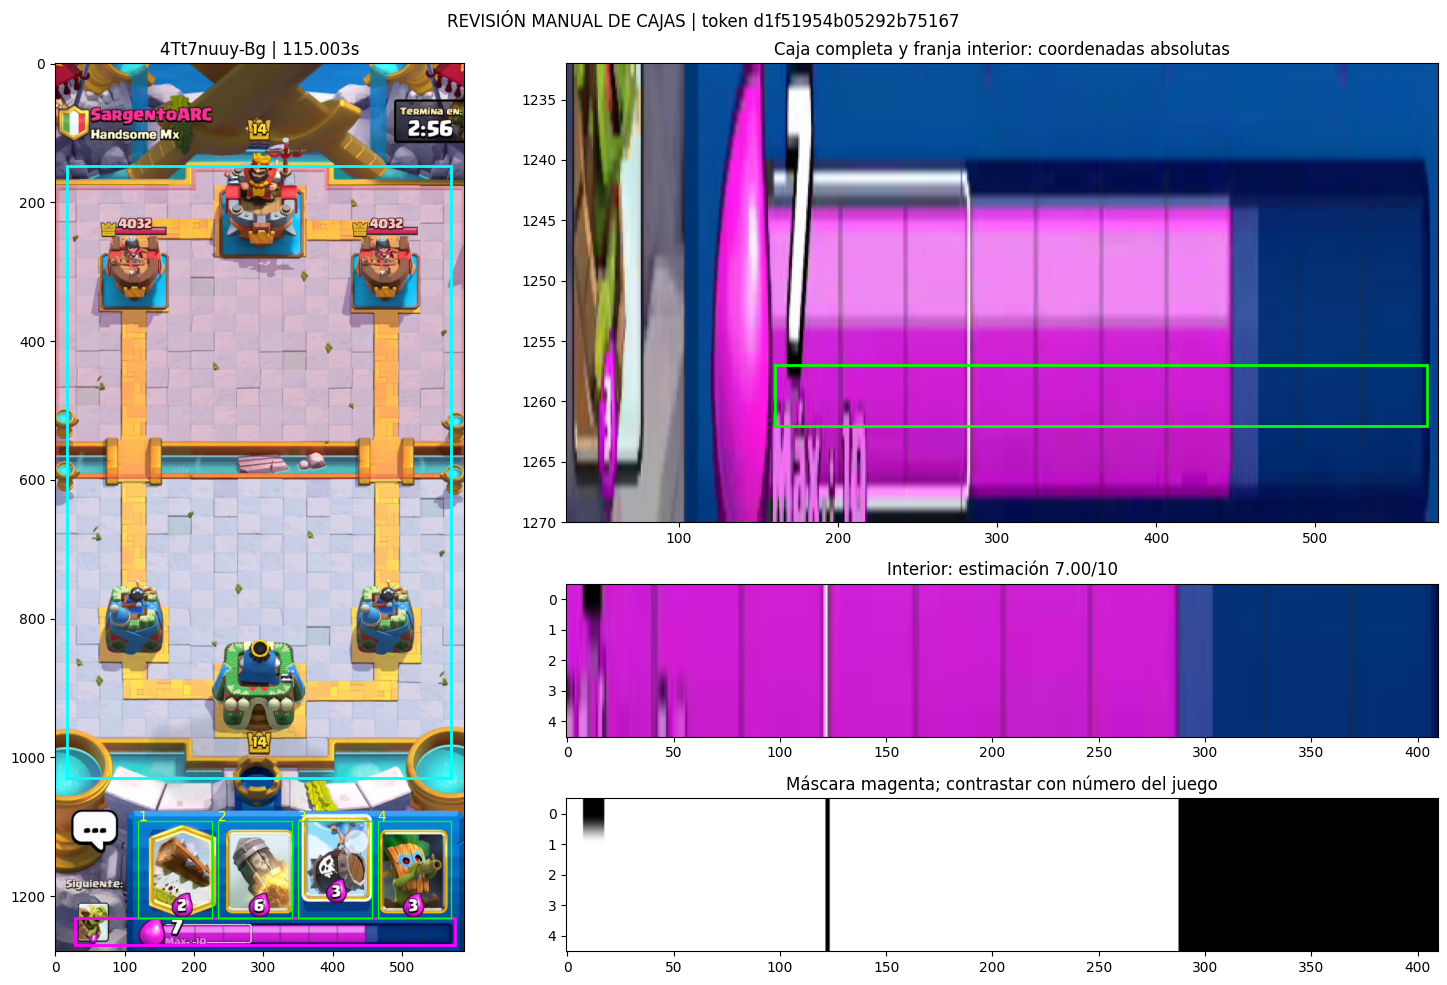

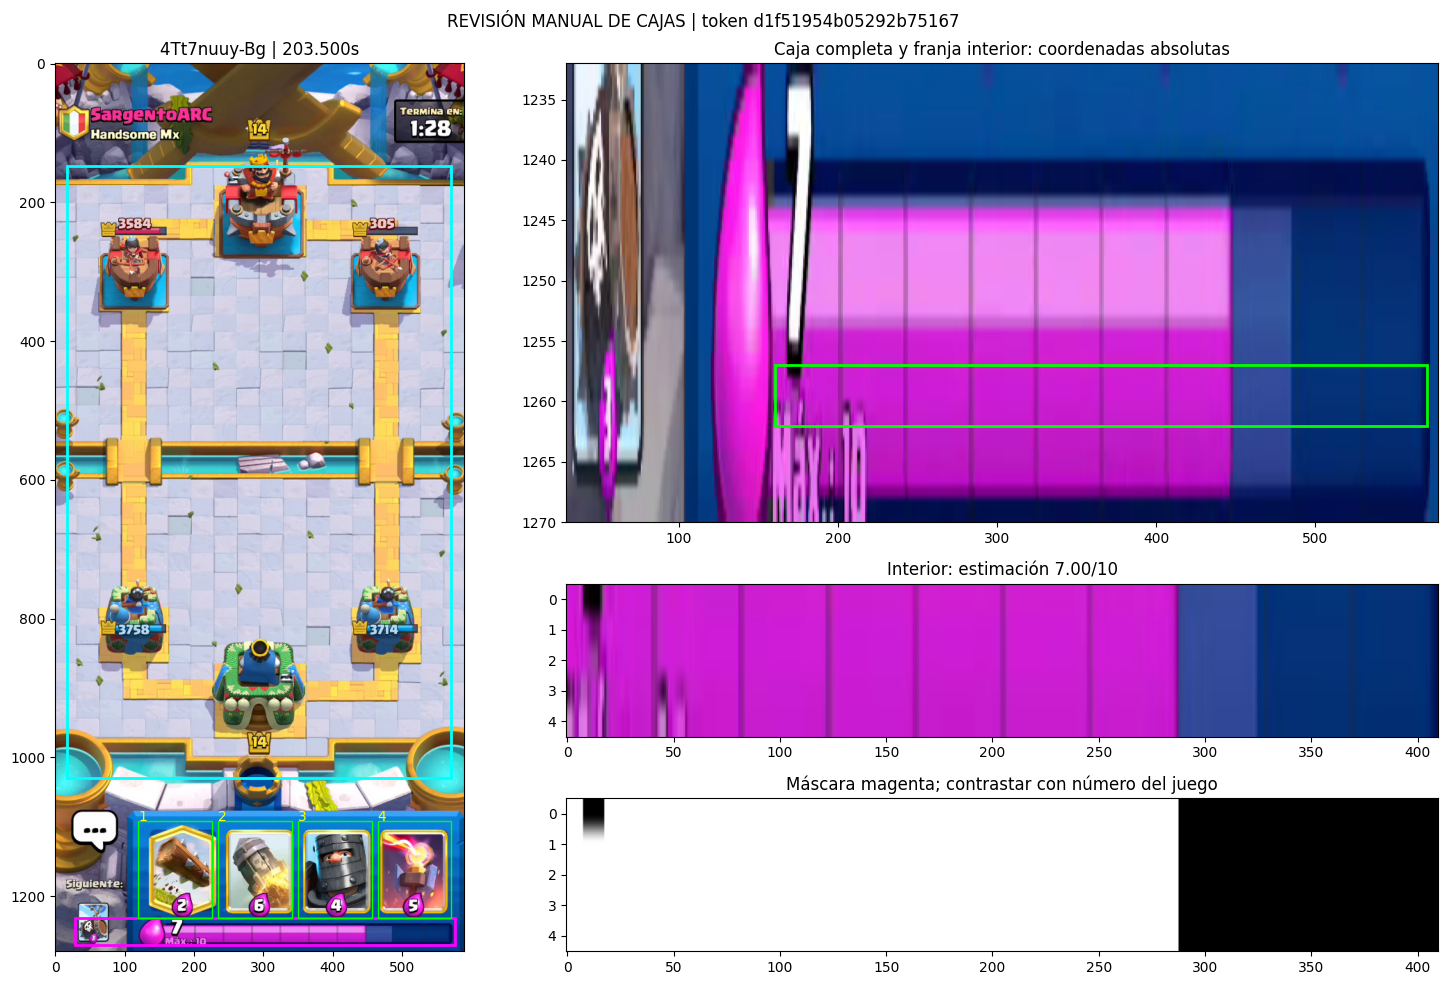

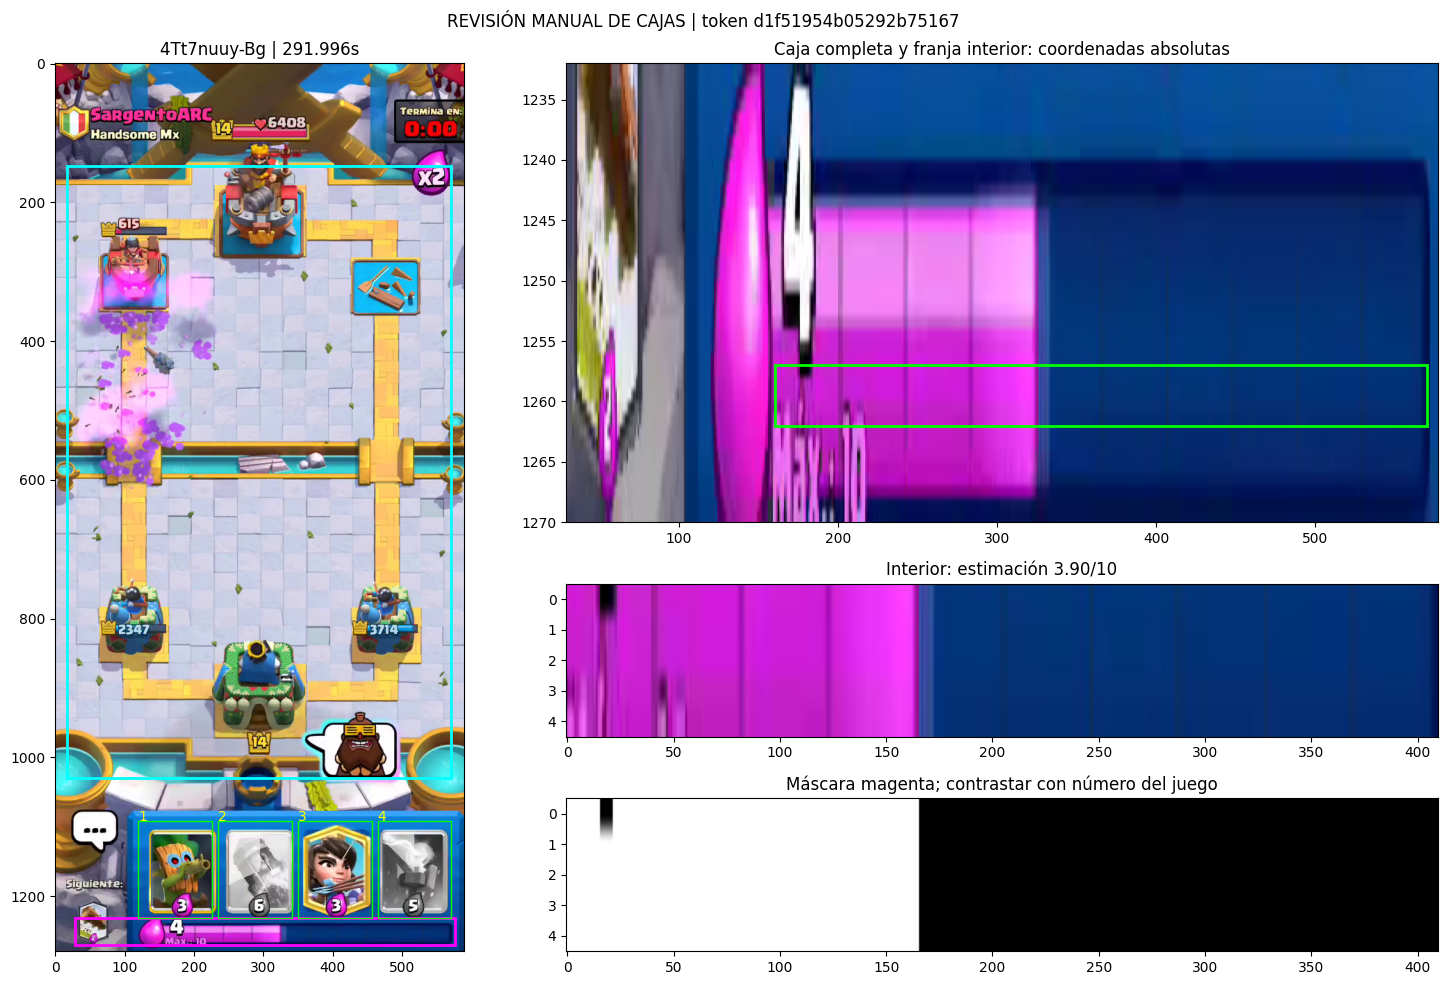

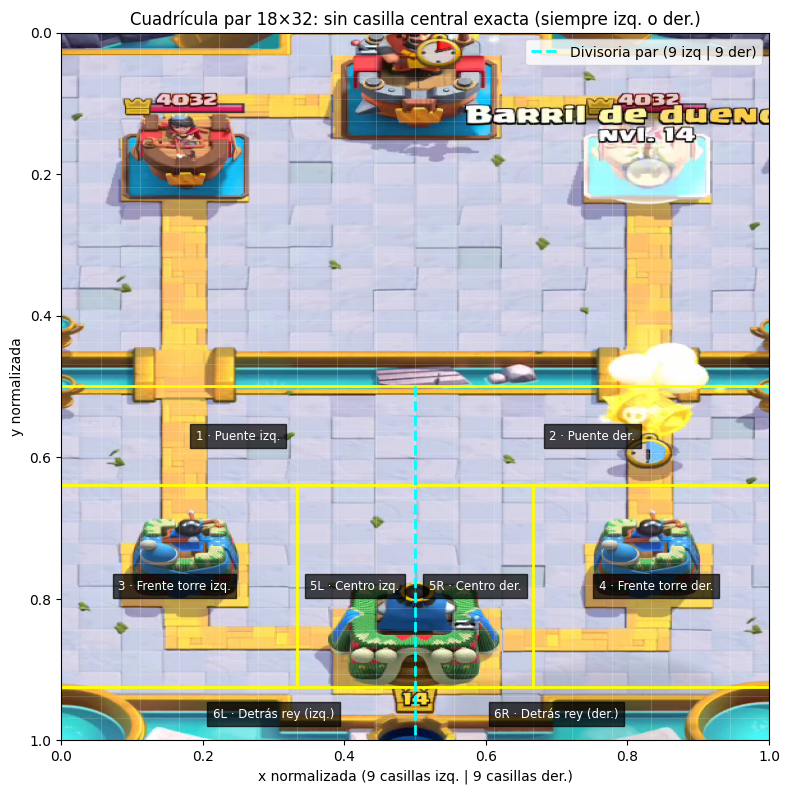

Contrasta la estimación de elixir con el número visible en los tres instantes.
Verifica la línea divisoria central (9 casillas a la izquierda, 9 a la derecha) en plot_zones.


In [142]:
for t in np.linspace(START + 1, END - 1, 3):
    fig = pipe.plot_layout(float(t))
    plt.show()
    plt.close(fig)
fig = pipe.plot_zones()
plt.show()
plt.close(fig)
print('Contrasta la estimación de elixir con el número visible en los tres instantes.')
print('Verifica la línea divisoria central (9 casillas a la izquierda, 9 a la derecha) en plot_zones.')

In [143]:
APPROVE_LAYOUT = True
APPROVE_ZONES = True

if (VIDEO_ID != '4Tt7nuuy-Bg' or [WIDTH, HEIGHT] != [590, 1280]
        or BAR_TRACK_XYWH != [160, 1257, 410, 5]):
    raise ValueError('La aprobación anterior corresponde al piloto. Revisar las cajas de esta nueva configuración.')
if APPROVE_LAYOUT:
    pipe.approve_layout(pipe.run_id)
if APPROVE_ZONES:
    pipe.approve_zones(pipe.run_id)
print('Cajas revisadas:', pipe.layout_approved, '| zonas revisadas:', pipe.zones_approved)

Cajas revisadas: True | zonas revisadas: True


## 4. Fase 1: Escanear señales, filtrar toques en mano y detectar eventos ($t_{\text{drop}}$)
Se agrupan los descensos consecutivos de elixir ($\Delta E \le -1.5$ como caída principal y soporte para ciclado de coste 1) y se mide la rotación en los 4 slots. Los toques sin caída de elixir quedan descartados como `selection_diagnostic`, y el menú azul de chat pausa las detecciones.

Escaneados 30/179s
Escaneados 60/179s
Escaneados 90/179s
Escaneados 120/179s
Escaneados 150/179s
1790 muestras. Candidatos de chat: 0. Pendiente de revisión.
Candidatos de despliegue/casos débiles: 34


,candidate_id,timestamp_sec,relative_sec,drop_estimate,slot_candidate,signal,event_type,occluded,review_status,native_interval,elixir_uncertain,slot_scores,low_cost
0,78848fab3e46b8db6491,120.512391,6.512391,3.05,NaN,revisar_caida,play_candidate,False,pending,"[120.41192230408573, 120.61286001339585]",False,"[0.008881739340722561, 0.00744383130222559, 0....",False
1,6f801644da914edbdee2,122.103148,8.103148,2.75,2.0,doble_señal,play_candidate,False,pending,"[122.00267916945747, 122.10314802411251]",False,"[0.012094566598534584, 0.1611468493938446, 0.0...",False
2,e7c868a9e982dc8de191,123.409243,9.409243,1.00,3.0,doble_señal,play_candidate,False,pending,"[123.3087742799732, 123.40924313462826]",False,"[0.11020322889089584, 0.08158394694328308, 0.4...",True
3,a7aae4201dc20a915bc1,123.610181,9.610181,2.00,3.0,doble_señal,play_candidate,False,pending,"[123.50971198928332, 123.61018084393838]",False,"[0.10003574192523956, 0.08290032297372818, 0.4...",False
4,04dd423fbd049b830e8b,134.209645,20.209645,2.00,3.0,doble_señal,play_candidate,False,pending,"[134.10917615539182, 134.20964501004687]",False,"[0.008201593533158302, 0.1099928542971611, 0.3...",False
5,927980933c9760c9b0dd,134.410583,20.410583,1.00,3.0,doble_señal,play_candidate,False,pending,"[134.31011386470195, 134.410582719357]",False,"[0.008130106143653393, 0.11324753612279892, 0....",True
6,5ff4c4d618ce3bc504ac,143.302076,29.302076,4.60,3.0,doble_señal,play_candidate,False,pending,"[143.2016075016745, 143.30207635632954]",False,"[0.177933007478714, 0.15330371260643005, 0.348...",False
7,d111611afd06f9d2c4fd,147.806430,33.806430,1.60,NaN,slot_ambiguo,play_candidate,False,pending,"[147.70596115204287, 147.80643000669792]",False,"[0.0055678109638392925, 0.033930759876966476, ...",False
8,78b70a17799ac3b82f07,174.112525,60.112525,3.35,4.0,doble_señal,play_candidate,False,pending,"[174.0120562625586, 174.11252511721366]",False,"[0.136813223361969, 0.00865911040455103, 0.006...",False
9,d35b307cd9952ac29b44,175.703282,61.703282,2.00,4.0,revisar_destello,play_candidate,False,pending,"[175.2009377093101, 175.70328198258537]",True,"[0.017343752086162567, 0.15860192477703094, 0....",False


,event_type,signal,cantidad
0,play_candidate,doble_señal,24
1,play_candidate,revisar_caida,1
2,play_candidate,revisar_destello,4
3,play_candidate,slot_ambiguo,5
4,selection_diagnostic,seleccion_sin_gasto,69


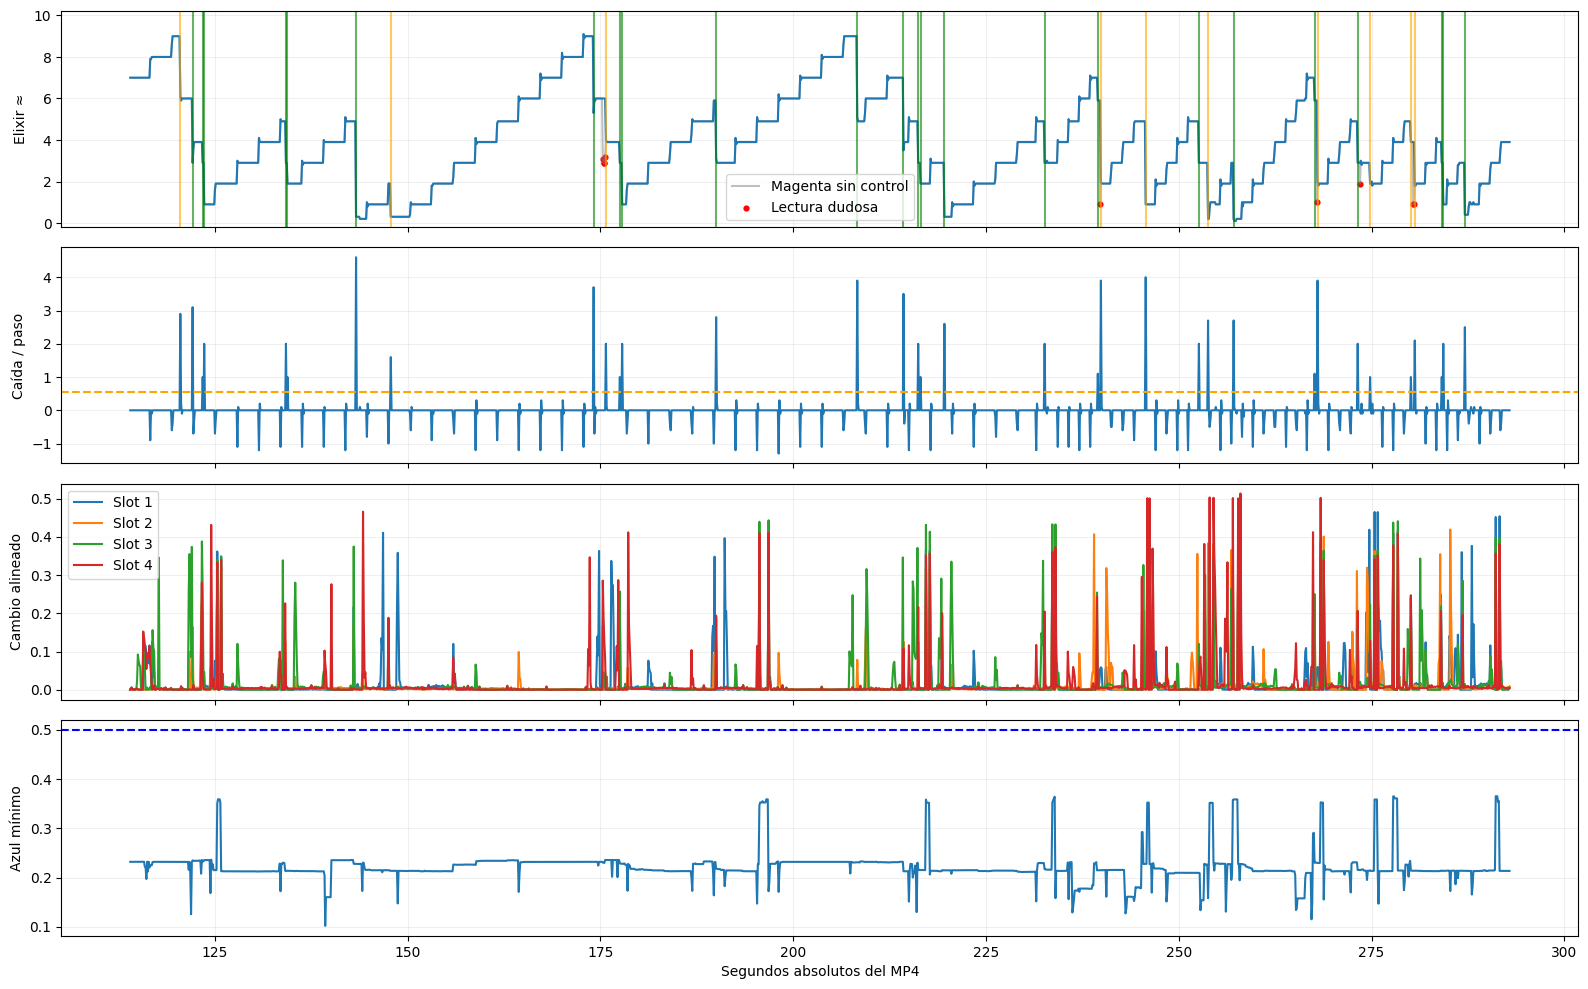

Lecturas dudosas: 9


In [144]:
signals = pipe.scan(use_cache=True)
events = pipe.detect()
print('Candidatos de despliegue/casos débiles:', len(events))
display(events)
all_events = pipe.table(include_selections=True)
if not all_events.empty:
    display(all_events.groupby(['event_type', 'signal']).size().rename('cantidad').reset_index())
fig = pipe.plot_timeline()
fig.savefig(pipe.root / 'timeline.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)
print("Lecturas dudosas:", int(signals.elixir_uncertain.sum()))

### Diagnóstico del elixir: bruto, fiable y huecos cortos

,timestamp_sec,elixir_raw,elixir_observed,elixir,elixir_flash,elixir_uncertain,elixir_filled
55,119.507703,9.0,9.0,9.0,False,False,False
56,119.608171,9.0,9.0,9.0,False,False,False
57,119.708640,9.0,9.0,9.0,False,False,False
58,119.809109,9.0,9.0,9.0,False,False,False
59,119.909578,9.0,9.0,9.0,False,False,False
60,120.010047,9.0,9.0,9.0,False,False,False
61,120.110516,9.0,9.0,9.0,False,False,False
62,120.210985,9.0,9.0,9.0,False,False,False
63,120.311453,9.0,9.0,9.0,False,False,False
64,120.411922,9.0,9.0,9.0,False,False,False


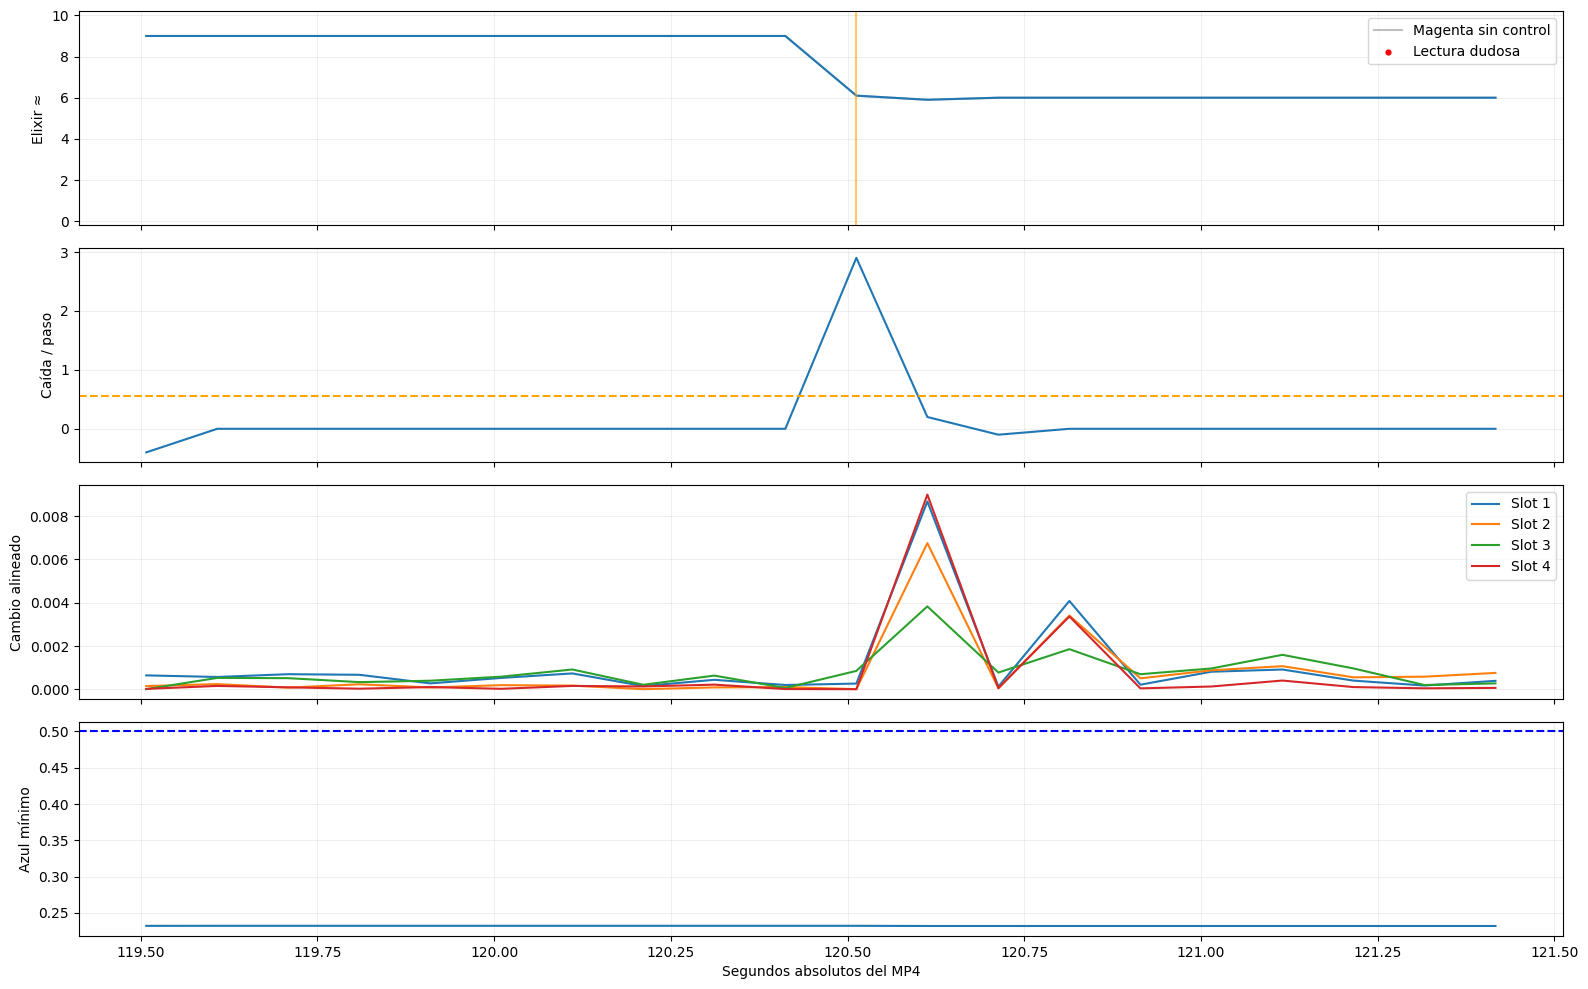

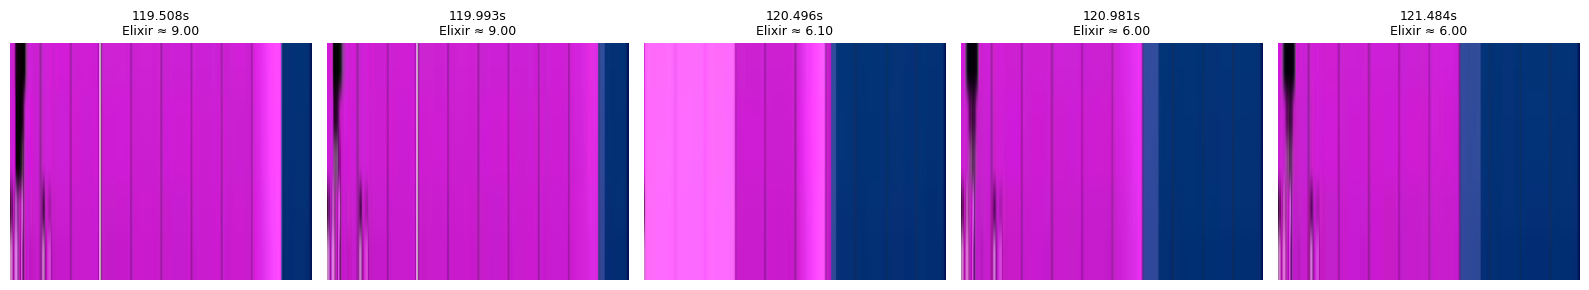

In [145]:
ELIXIR_DIAG_START = max(START, 119.5) if START <= 120.5 < END else START
ELIXIR_DIAG_END = min(END, ELIXIR_DIAG_START + 2.0)

s = pipe.signals[pipe.signals.timestamp_sec.between(ELIXIR_DIAG_START, ELIXIR_DIAG_END)]
display(s[['timestamp_sec', 'elixir_raw', 'elixir_observed', 'elixir',
           'elixir_flash', 'elixir_uncertain', 'elixir_filled']])
fig = pipe.plot_timeline(ELIXIR_DIAG_START, ELIXIR_DIAG_END)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, t in zip(axes, np.linspace(ELIXIR_DIAG_START, ELIXIR_DIAG_END - .02, 5)):
    frame, actual = pipe.video.frame(float(t))
    bar = crop(frame, pipe.bar)
    reading = elixir_observation(bar, pipe.p)
    ax.imshow(bar, aspect='auto')
    label = 'DESTELLO: sin lectura' if reading['flash'] else f"Elixir ≈ {reading['value']:.2f}"
    ax.set_title(f'{actual:.3f}s\n{label}', fontsize=9)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

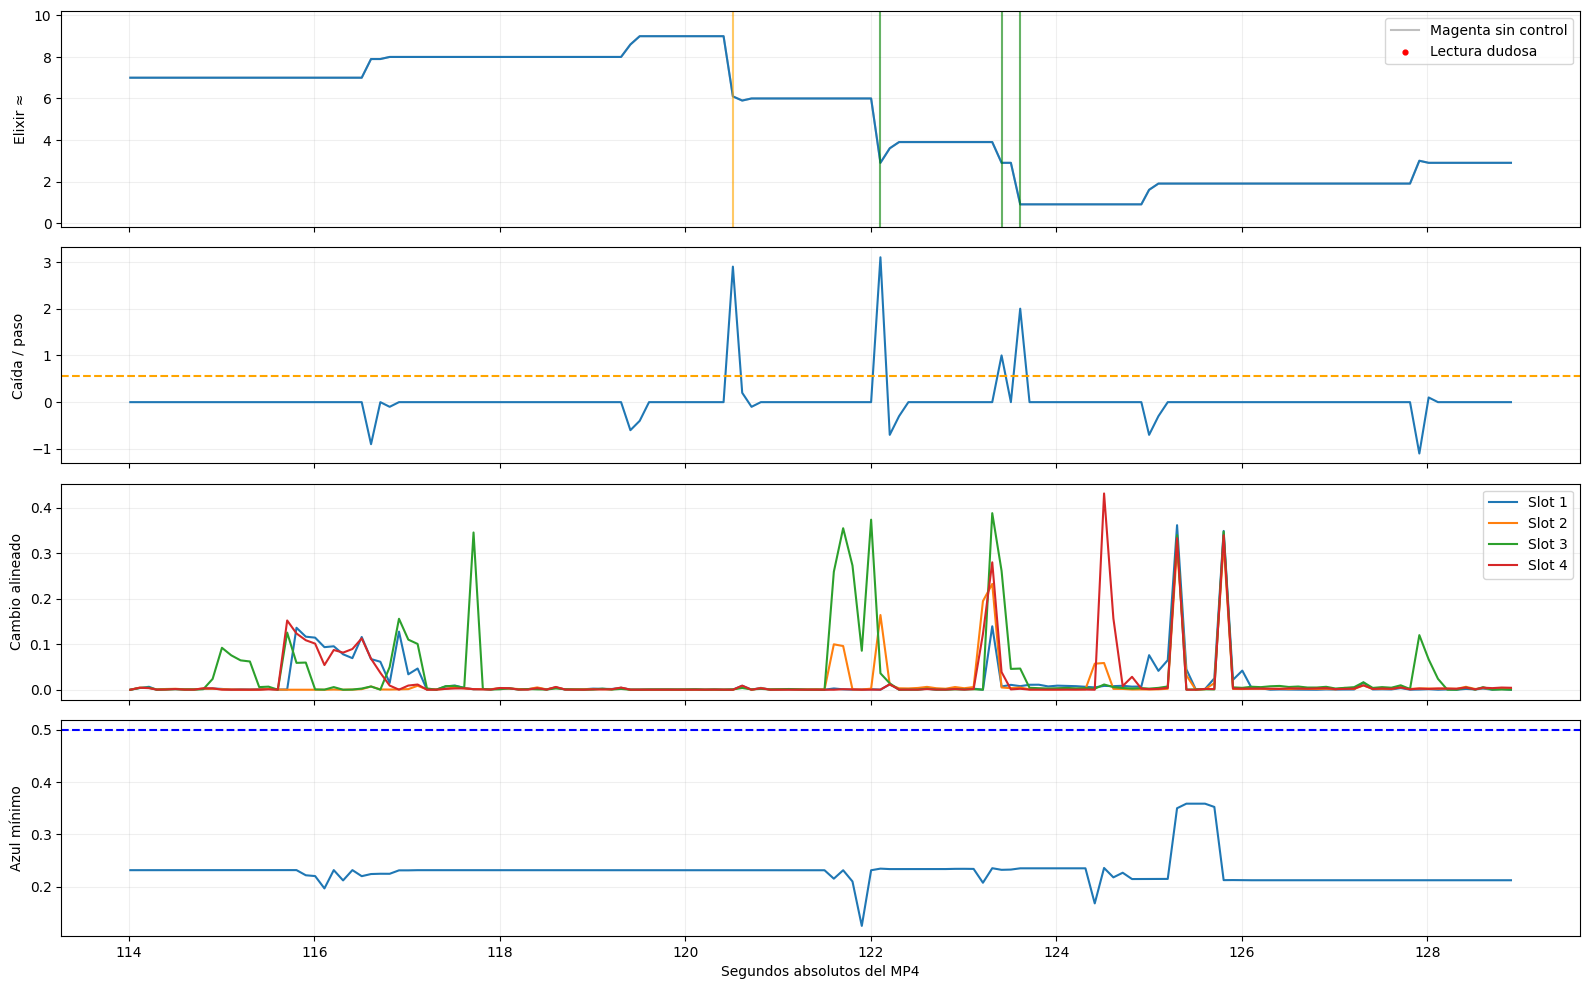

In [146]:
ZOOM_START = START
ZOOM_END = min(END, START + 15)
fig = pipe.plot_timeline(ZOOM_START, ZOOM_END)
plt.show()
plt.close(fig)

## 5. Fase 2: Catálogo de Cartas (incluyendo Evoluciones) y Asociación con la Jugada
De acuerdo con `action-extraction-spec.pdf` y `AGENTS.md`, el banco canónico incluye tanto las cartas normales como sus versiones evolucionadas (`normal` y `evolved`), cruzando identidad previa en $t_{\text{drop}} - 0.8\text{ s}$, rotación posterior del slot y consistencia con la caída de elixir.

In [147]:
"""Banco automático de RoyaleAPI: incluye cartas normales y evolucionadas permitidas."""
import hashlib
import json
import re
import shutil
import subprocess
import unicodedata
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ASSETS_URL = 'https://github.com/RoyaleAPI/cr-api-assets.git'
DATA_URL = 'https://github.com/RoyaleAPI/cr-api-data.git'
ALLOWED_RARITIES = {'common', 'rare', 'epic', 'legendary'}
EVOLVED_SUFFIX_RE = re.compile(r'^(?P<base>.+?)[-_](?:ev\d+|evolved|evolution)$', re.I)
EXCLUDED_HERO_RE = re.compile(r'(?:^|[-_])(?:hero(?:es)?|champion|super[-_])(?:$|[-_])', re.I)
AUTO_CARD_VERSION = '3.5-rotation-cost-evolved-1.0'

In [148]:
def _norm_name(text):
    text = unicodedata.normalize('NFKD', str(text)).casefold()
    return ''.join(c for c in text if c.isalnum())

In [149]:
def _git(args, cwd=None):
    try:
        result = subprocess.run(['git', *args], cwd=cwd, check=True, capture_output=True,
                                text=True, timeout=300)
    except FileNotFoundError as error:
        raise RuntimeError('Git no está instalado en el kernel. Instalar git o indicar clones locales.') from error
    except subprocess.TimeoutExpired as error:
        raise RuntimeError('Git superó 300 s; revisar Internet en Kaggle.') from error
    except subprocess.CalledProcessError as error:
        raise RuntimeError('No se pudo leer el repositorio de RoyaleAPI: '+error.stderr[-600:]) from error
    return result.stdout.strip()

In [150]:
def ensure_sparse_clone(url, target, directories):
    target = Path(target)
    if target.exists():
        if not (target/'.git').exists():
            raise ValueError(f'La carpeta {target} existe pero no es un clon; no se borra.')
        origin = _git(['remote','get-url','origin'],target).rstrip('/')
        if origin.removesuffix('.git') != url.removesuffix('.git'):
            raise ValueError('La carpeta apunta a otro repositorio; no se modifica.')
        if not all((target/d).exists() for d in directories):
            raise ValueError('Clon incompleto. Usar una carpeta de caché nueva o descargar sus carpetas faltantes.')
    else:
        target.parent.mkdir(parents=True,exist_ok=True)
        temporary = target.with_name(target.name+'.partial')
        if temporary.exists():
            raise RuntimeError(f'Hay una descarga parcial en {temporary}; revisarla o usar otra ruta.')
        _git(['clone','--depth','1','--filter=blob:none','--sparse',url,str(temporary)])
        _git(['sparse-checkout','set',*directories],temporary)
        temporary.replace(target)
    return _git(['rev-parse','HEAD'],target)

#### Catálogo de imágenes y metadatos (Normal + Evolved)

In [151]:
def build_royale_catalog(cache_root, assets_dir=None, data_dir=None, include_evolved=True):
    """Une assets + cards.json + traducciones oficiales en español (incluyendo evolucionadas)."""
    root=Path(cache_root);root.mkdir(parents=True,exist_ok=True)
    assets=Path(assets_dir) if assets_dir else root/'cr-api-assets'
    data=Path(data_dir) if data_dir else root/'cr-api-data'
    if assets_dir:
        if not (assets/'cards-150').is_dir():raise ValueError('Falta cards-150 en assets_dir.')
        asset_commit=_git(['rev-parse','HEAD'],assets) if (assets/'.git').exists() else 'local'
    else:asset_commit=ensure_sparse_clone(ASSETS_URL,assets,['cards-150'])
    if data_dir:
        if not (data/'docs/json/cards.json').exists():raise ValueError('Falta docs/json/cards.json en data_dir.')
        data_commit=_git(['rev-parse','HEAD'],data) if (data/'.git').exists() else 'local'
    else:data_commit=ensure_sparse_clone(DATA_URL,data,['docs/json'])
    cards=json.loads((data/'docs/json/cards.json').read_text(encoding='utf-8'))
    texts_path=data/'docs/json/texts.json'
    if not texts_path.exists():raise ValueError('Falta texts.json para obtener nombres en español.')
    texts=json.loads(texts_path.read_text(encoding='utf-8'))
    translations={}
    for key,value in texts.items():
        if key.startswith('TID_SPELL_') and isinstance(value,dict) and value.get('en') and value.get('es'):
            translations.setdefault(_norm_name(value['en']),set()).add(value['es'].strip())
    metadata={c['key']:c for c in cards}
    entries=[];diagnostics=[];images=sorted((assets/'cards-150').glob('*.png'))
    for path in images:
        key=path.stem
        if key.startswith('_'):continue
        evo_match = EVOLVED_SUFFIX_RE.match(key)
        base_key = evo_match.group('base') if evo_match else key
        item = metadata.get(key) or metadata.get(base_key)
        is_evo = bool(evo_match or (item and item.get('is_evolved') is True))
        reasons=[]
        if EXCLUDED_HERO_RE.search(key):reasons.append('heroe_o_campeon_excluido')
        if is_evo and not include_evolved:reasons.append('evolucion_desactivada')
        if item is None:reasons.append('sin_metadatos_exactos')
        else:
            if str(item.get('rarity','')).casefold() not in ALLOWED_RARITIES:reasons.append('rareza_excluida')
            if item.get('is_hero') is True:reasons.append('variante_heroe_excluida')
            if str(item.get('type','')).casefold() not in {'troop','building','spell'}:reasons.append('tipo_no_jugable_en_mano')
        names=translations.get(_norm_name(item.get('name','')) if item else '',set())
        if item and len(names)!=1:reasons.append('traduccion_ausente_o_ambigua')
        cost=item.get('elixir') if item else None
        if item and (not isinstance(cost,int) or not 0<=cost<=10):reasons.append('coste_no_resuelto')
        allowed=not reasons
        label=next(iter(names)) if len(names)==1 else (item.get('name',key) if item else key)
        image=cv2.imread(str(path),cv2.IMREAD_UNCHANGED)
        if image is None:
            diagnostics.append({'key':key,'reason':'imagen_ilegible'});continue
        variant = ('evolved' if is_evo else 'normal') if allowed else 'excluded'
        entry={'key':key,'base_key':base_key,'name_es':label,'cost':cost,'variant':variant,
               'kind':str(item.get('type','unknown')).casefold() if item else 'unknown',
               'rarity':item.get('rarity') if item else None,'allowed':allowed,
               'image':str(path.resolve()),'reasons':reasons,'special_cost':base_key=='mirror',
               'provenance':f'RoyaleAPI assets {asset_commit}; data {data_commit}'}
        entries.append(entry)
        if reasons:diagnostics.append({'key':key,'reason':';'.join(reasons)})
    allowed_keys={e['base_key'] for e in entries if e['allowed']}
    for key,item in metadata.items():
        if str(item.get('rarity','')).casefold() in ALLOWED_RARITIES and key not in allowed_keys:
            diagnostics.append({'key':key,'reason':'sin_referencia_permitida; revisar cobertura'})
    report={'version':AUTO_CARD_VERSION,'assets_commit':asset_commit,'data_commit':data_commit,
            'assets_repo':ASSETS_URL,'metadata_repo':DATA_URL,'allowed_rarities':sorted(ALLOWED_RARITIES),
            'allowed_count':sum(e['allowed'] for e in entries),
            'evolved_count':sum(e['allowed'] and e['variant']=='evolved' for e in entries),
            'guard_count':sum(not e['allowed'] for e in entries),
            'diagnostics':diagnostics,'catalog':entries}
    (root/'royale_catalog.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    pd.DataFrame(diagnostics).to_csv(root/'catalog_coverage.csv',index=False)
    if not allowed_keys:raise RuntimeError('No se pudo construir un catálogo permitido.')
    return entries,report

In [152]:
def _asset_rgb(path):
    image=cv2.imread(str(path),cv2.IMREAD_UNCHANGED)
    if image is None:raise ValueError('Asset ausente o ilegible.')
    if image.ndim==2:return cv2.cvtColor(image,cv2.COLOR_GRAY2RGB)
    if image.shape[2]==4:
        rgb=cv2.cvtColor(image[:,:,:3],cv2.COLOR_BGR2RGB).astype(float)
        alpha=image[:,:,3:4].astype(float)/255
        return (rgb*alpha+40*(1-alpha)).astype(np.uint8)
    return cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

#### Comparación visual con las referencias

In [153]:
class _RoyaleMatching:
    def rank(self,rgb,p=None):
        if rgb is None or rgb.size==0:return []
        identity=hashlib.sha256(rgb.tobytes()+str(rgb.shape).encode()).hexdigest()
        if identity in self._query_cache:return self._query_cache[identity]
        height=128;width=max(32,round(rgb.shape[1]*height/rgb.shape[0]))
        query=cv2.resize(rgb,(width,height),interpolation=cv2.INTER_AREA)
        gray=cv2.cvtColor(query,cv2.COLOR_RGB2GRAY)
        edge_density=float((cv2.Canny(gray,60,140)>0).mean())
        if gray.std()<9 or edge_density<.018:
            self._query_cache[identity]=[];return []
        matches=[]
        for entry,patch,template_gray in self._templates:
            best=None
            for fraction in [.58,.66,.74,.82,.90]:
                tw=max(12,round(width*fraction));th=round(tw*template_gray.shape[0]/template_gray.shape[1])
                if tw>width or th>height:continue
                templ=cv2.resize(template_gray,(tw,th),interpolation=cv2.INTER_AREA)
                if templ.std()<2:continue
                corrmap=cv2.matchTemplate(gray,templ,cv2.TM_CCOEFF_NORMED)
                _,corr,_,pos=cv2.minMaxLoc(corrmap)
                if not np.isfinite(corr):continue
                x,y=pos;observed=query[y:y+th,x:x+tw]
                reference=cv2.resize(patch,(tw,th),interpolation=cv2.INTER_AREA)
                observed_hsv=cv2.cvtColor(observed,cv2.COLOR_RGB2HSV)
                ref_hsv=cv2.cvtColor(reference,cv2.COLOR_RGB2HSV)
                a=cv2.calcHist([observed_hsv],[0,1],None,[12,8],[0,180,0,256]);cv2.normalize(a,a)
                b=cv2.calcHist([ref_hsv],[0,1],None,[12,8],[0,180,0,256]);cv2.normalize(b,b)
                color=1-float(cv2.compareHist(a,b,cv2.HISTCMP_BHATTACHARYYA))
                weight=.92 if np.median(observed_hsv[:,:,1])<45 else .82
                score=weight*max(0.,corr)+(1-weight)*max(0.,color)
                candidate=dict(entry,score=float(score),correlation=float(corr),
                               match_box=[x/width,y/height,tw/width,th/height])
                if best is None or score>best['score']:best=candidate
            if best:matches.append(best)
        matches.sort(key=lambda r:r['score'],reverse=True)
        self._query_cache[identity]=matches[:8]
        return matches[:8]

    def classify(self,rgb,drop_estimate=None):
        ranks=self.rank(rgb)
        if not ranks:return {'state':'no_identificable','alternatives':[]}
        first=ranks[0];second=ranks[1]['score'] if len(ranks)>1 else first['score']
        margin=first['score']-second
        base={'alternatives':ranks[:4],'score':first['score'],'margin':margin,
              'suggested_name':first['name_es'],'suggested_key':first['key']}
        clear=first['score']>=self.min_score and first['correlation']>=self.min_correlation and margin>=self.min_margin
        if not clear:return dict(base,state='ambiguo')
        if not first['allowed']:
            explicit=any(r in first['reasons'] for r in ['heroe_o_campeon_excluido','rareza_excluida','variante_heroe_excluida'])
            return dict(base,state='excluida_del_proyecto' if explicit else 'fuera_del_catalogo',exclusion_reasons=first['reasons'])
        consistent=None if drop_estimate is None else abs(float(drop_estimate)-first['cost'])<=.65
        return dict(base,state='propuesta',name_es=first['name_es'],card_key=first['key'],cost=first['cost'],
                    variant=first['variant'],kind=first['kind'],reference=first['image'],
                    cost_consistent=consistent,special_cost=first['special_cost'])

#### Validación del catálogo y del alcance

In [154]:
class _RoyaleValidation:
    def validate_label(self,name,cost,variant,kind):
        if variant not in {'normal','evolved'}:
            raise ValueError('Variante inválida: usar normal o evolved.')
        matches=[e for e in self.entries if e['name_es']==name and e['variant']==variant]
        if not matches:
            matches=[e for e in self.entries if e['name_es']==name]
        if not matches:raise ValueError('La carta no pertenece al catálogo permitido.')
        entry=matches[0]
        if entry['kind']!=kind:raise ValueError('Tipo de carta distinto del catálogo.')
        if not entry['special_cost'] and int(cost)!=entry['cost']:
            raise ValueError('Coste distinto del catálogo. Revisar identificación o evento.')
        return True

    def assert_frame_scope(self,frame,slots):
        for number,box in enumerate(slots,1):
            x,y,w,h=map(int,box);result=self.classify(frame[y:y+h,x:x+w])
            if result['state'] in {'excluida_del_proyecto','fuera_del_catalogo'}:
                raise ValueError(f'Entrada contiene una carta excluida en slot {number}: {result["suggested_name"]}.')

In [155]:
class RoyaleAutoBank(_RoyaleMatching, _RoyaleValidation):
    def __init__(self, entries, report, min_score=.72, min_margin=.045, min_correlation=.67):
        self.root=Path('/')
        self.entries=[dict(e) for e in entries if e['allowed']]
        self.references=[dict(e) for e in entries]
        self.report=report
        self.min_score=float(min_score);self.min_margin=float(min_margin);self.min_correlation=float(min_correlation)
        self._templates=[];self._query_cache={}
        h=hashlib.sha256(json.dumps({'version':AUTO_CARD_VERSION,'report':report,
                         'thresholds':[min_score,min_margin,min_correlation]},sort_keys=True).encode())
        for entry in self.references:
            image=_asset_rgb(entry['image']);hh,ww=image.shape[:2]
            patch=image[int(hh*.16):int(hh*.80),int(ww*.16):int(ww*.84)]
            gray=cv2.cvtColor(patch,cv2.COLOR_RGB2GRAY)
            self._templates.append((entry,patch,gray))
            h.update(Path(entry['image']).read_bytes())
        self._fingerprint=h.hexdigest()[:20]

    @property
    def fingerprint(self):return self._fingerprint

    def add(self,*args,**kwargs):
        raise RuntimeError('Este banco es automático: no requiere capturas ni etiquetas manuales.')

In [156]:
def install_royaleapi_bank(pipe,cache_root,assets_dir=None,data_dir=None,
                           min_score=.72,min_margin=.045,min_correlation=.67,include_evolved=True):
    entries,report=build_royale_catalog(cache_root,assets_dir,data_dir,include_evolved=include_evolved)
    bank=RoyaleAutoBank(entries,report,min_score,min_margin,min_correlation)
    pipe.bank=bank
    pipe.preview_tokens.clear()
    pipe.loaded_bank_hash=bank.fingerprint
    print('Cartas permitidas (normales + evolucionadas):',report['allowed_count'],
          f"(evolucionadas: {report.get('evolved_count', 0)})")
    print('Referencias excluidas/negativas:',report['guard_count'])
    print('Cobertura y excepciones:',Path(cache_root)/'catalog_coverage.csv')
    return bank

In [157]:
def plot_auto_hand(pipe,timestamp):
    frame,actual=pipe.video.frame(float(timestamp))
    fig,axes=plt.subplots(4,4,figsize=(13,12))
    results=[]
    for slot,box in enumerate(pipe.boxes['card_slots'],1):
        x,y,w,h=map(int,box);image=frame[y:y+h,x:x+w]
        result=pipe.bank.classify(image);results.append(dict(slot=slot,**{k:v for k,v in result.items() if k!='alternatives'}))
        axes[slot-1,0].imshow(image);axes[slot-1,0].set_title(f'Slot {slot}: {result.get("name_es",result["state"])}')
        for ax in axes[slot-1,:]:ax.axis('off')
        for col,rank in enumerate(result.get('alternatives',[])[:3],1):
            axes[slot-1,col].imshow(_asset_rgb(rank['image']))
            tag=rank['variant'].upper() if rank['allowed'] else 'EXCLUIDA'
            axes[slot-1,col].set_title(f'{rank["name_es"]}\n{rank["score"]:.3f} | {tag}',fontsize=9)
    fig.suptitle(f'Identificación automática en {actual:.3f}s · propuestas pendientes de revisión')
    fig.tight_layout(rect=[0,0,1,.96]);return fig,pd.DataFrame(results)

#### Asociar gasto, rotación del slot y carta

In [158]:
def associate_play(pipe, event, timestamp=None, requested_slot=None):
    """Cruza identidad previa, reemplazo posterior y gasto; nunca elige solo por coste."""
    t=float(event['timestamp_sec'] if timestamp is None else timestamp)
    drop=float(event.get('drop_estimate',0))
    signals=getattr(pipe,'signals',None)
    if signals is not None and 'elixir_uncertain' in signals:
        good=signals[~signals.elixir_uncertain & signals.elixir.notna()]
        pre=good[good.timestamp_sec.between(t-.25,t-.05)].elixir
        post=good[good.timestamp_sec.between(t+.05,t+.25)].elixir
        if len(pre)>=2 and len(post)>=2 and float(pre.median()-post.median())>=.5:
            drop=float(pre.median()-post.median())
    if requested_slot == 0:requested_slot=None
    if requested_slot is not None and requested_slot not in [1,2,3,4]:
        return {'state':'slot_invalido','alternatives':[]}
    cache=getattr(pipe,'_association_cache',None)
    if cache is None:pipe._association_cache={};cache=pipe._association_cache
    key=(pipe.bank.fingerprint,event.get('candidate_id'),round(t,6),drop)
    if key not in cache:
        rows=[];hypotheses=[];frames={}
        def query(slot,offset):
            at=t+offset
            if not pipe.video.start<=at<pipe.video.end:return None
            if offset not in frames:frames[offset]=pipe.video.frame(at)
            frame,actual=frames[offset];x,y,w,h=map(int,pipe.boxes['card_slots'][slot-1])
            image=frame[y:y+h,x:x+w]
            result=pipe.bank.classify(image)
            return dict(result,slot_image=image,source_time=actual,source_offset=-offset,hand_slot=slot)
        for slot in range(1,5):
            before=None
            for offset in [-.8,-1.4,-2.2,-3.4]:
                item=query(slot,offset)
                if item is not None and item['state'] in {'propuesta','excluida_del_proyecto','fuera_del_catalogo'}:
                    before=item;break
            after=None
            for offset in [.7,.4]:
                item=query(slot,offset)
                if item is not None and item['state'] in {'propuesta','excluida_del_proyecto','fuera_del_catalogo'}:
                    after=item;break
            before_key=before.get('card_key',before.get('suggested_key')) if before else None
            after_key=after.get('card_key',after.get('suggested_key')) if after else None
            changed=bool(before_key and after_key and before_key!=after_key)
            consistent=bool(before and before.get('cost') is not None and
                            not before.get('special_cost') and abs(before['cost']-drop)<=.65)
            transition_near=False
            if changed:
                near_before=query(slot,-.25)
                near_key=near_before.get('card_key',near_before.get('suggested_key')) if near_before else None
                transition_near=near_key is None or near_key==before_key
            state=('sin_historia_legible' if not before else
                   'sin_reemplazo_confirmado' if not after else
                   'misma_carta_en_mano' if not changed else
                   'rotacion_anterior_al_evento' if not transition_near else
                   'coste_incompatible' if not consistent else 'compatible')
            rows.append({'slot':slot,'carta_previa':before.get('name_es',before.get('suggested_name')) if before else None,
                         'variante_previa':before.get('variant') if before else None,
                         'carta_posterior':after.get('name_es',after.get('suggested_name')) if after else None,
                         'rotacion':changed,'coste_consistente':consistent,'estado':state,
                         'tiempo_referencia':before.get('source_time') if before else None})
            if state=='compatible' and before['state']=='propuesta':
                hypotheses.append(dict(before,cost_consistent=True,rotation_confirmed=True,
                                       association_state='rotacion_y_coste',state='propuesta',
                                       extended_history=before['source_offset']>.81))
        cache[key]=(rows,hypotheses)
    rows,hypotheses=cache[key]
    available=hypotheses if requested_slot is None else [h for h in hypotheses if h['hand_slot']==requested_slot]
    if len(hypotheses)==1 and len(available)==1:
        return dict(available[0],slot_diagnostics=rows)
    state='varios_slots_compatibles' if len(hypotheses)>1 else 'asociacion_no_resuelta'
    if requested_slot is not None and len(hypotheses)==1 and not available:state='slot_no_corresponde'
    return {'state':state,'alternatives':[],'slot_diagnostics':rows,
            'suggested_slot':hypotheses[0]['hand_slot'] if len(hypotheses)==1 else None,
            'cost_consistent':False}

In [159]:
def plot_slot_association(pipe,event,t=None):
    timestamp=float(event['timestamp_sec'] if t is None else t)
    result=associate_play(pipe,event,timestamp)
    fig,axes=plt.subplots(4,3,figsize=(10,11))
    for row,diagnostic in enumerate(result.get('slot_diagnostics',[])):
        reference=diagnostic.get('tiempo_referencia')
        reference=timestamp-.8 if reference is None else reference
        times=[reference,timestamp-.25,timestamp+.7]
        for col,(at,label) in enumerate(zip(times,['Referencia previa','Antes del gasto','Después'])):
            ax=axes[row,col];ax.axis('off')
            if not pipe.video.start<=at<pipe.video.end:continue
            frame,actual=pipe.video.frame(at)
            x,y,w,h=map(int,pipe.boxes['card_slots'][row])
            ax.imshow(frame[y:y+h,x:x+w]);ax.set_title(f'Slot {row+1} · {label}\n{actual:.3f}s',fontsize=9)
        axes[row,0].set_ylabel(diagnostic['estado'])
    fig.suptitle('Rotación de los cuatro slots · evidencia para revisión')
    fig.tight_layout(rect=[0,0,1,.97])
    return fig

In [160]:
def attach_royaleapi_to_existing_pipe(pipe):
    import types
    if hasattr(pipe,'_royale_original_identify'):
        return
    pipe._royale_original_identify=pipe.identify
    pipe._royale_original_payload=pipe._payload
    pipe._royale_original_frames=pipe._input_frames
    def identify(self,event,t=None,slot=None):
        return associate_play(self,event,t,slot)
    def payload(self,*args,**kwargs):
        value=self._royale_original_payload(*args,**kwargs)
        if value['action_type']=='play':
            self.bank.validate_label(value['card_name'],value['elixir_cost'],value['variant'],value['kind'])
            event=self._get_event(value['candidate_id'])
            result=self.identify(event,value['timestamp_sec'],value['hand_slot'])
            if result['state']!='propuesta' or result.get('name_es')!=value['card_name']:
                raise ValueError('Carta, slot y gasto sin asociación confirmada. Revisar el tiempo, los cuatro slots y la rotación; no aceptar esta muestra todavía.')
        return value
    def frames(self,value):
        images,times=self._royale_original_frames(value)
        for image in images:self.bank.assert_frame_scope(image,self.boxes['card_slots'])
        return images,times
    pipe.identify=types.MethodType(identify,pipe)
    pipe.plot_slot_association=types.MethodType(lambda self,event,t=None:plot_slot_association(self,event,t),pipe)
    pipe._payload=types.MethodType(payload,pipe)
    pipe._input_frames=types.MethodType(frames,pipe)

In [161]:
ROYALE_CACHE = PIPELINE_ROOT.parent / 'royaleapi_cache'
ASSETS_LOCAL_DIR = None
DATA_LOCAL_DIR = None

AUTO_MIN_SCORE = .72
AUTO_MIN_MARGIN = .045
AUTO_MIN_CORRELATION = .67

royale_bank = install_royaleapi_bank(
    pipe, ROYALE_CACHE,
    assets_dir=ASSETS_LOCAL_DIR, data_dir=DATA_LOCAL_DIR,
    min_score=AUTO_MIN_SCORE, min_margin=AUTO_MIN_MARGIN,
    min_correlation=AUTO_MIN_CORRELATION,
    include_evolved=True,
)
attach_royaleapi_to_existing_pipe(pipe)
display(pd.DataFrame(pipe.bank.entries)[['key','name_es','variant','rarity','cost','kind']])

Cartas permitidas (normales + evolucionadas): 153 (evolucionadas: 39)
Referencias excluidas/negativas: 51
Cobertura y excepciones: /kaggle/working/royaleapi_cache/catalog_coverage.csv


,key,name_es,variant,rarity,cost,kind
0,archers-ev1,Arqueras,evolved,Common,3,troop
1,archers,Arqueras,normal,Common,3,troop
2,arrows,Flechas,normal,Common,3,spell
3,baby-dragon-ev1,Bebé dragón,evolved,Epic,4,troop
4,baby-dragon,Bebé dragón,normal,Epic,4,troop
...,...,...,...,...,...,...
148,wizard,Mago,normal,Rare,5,troop
149,x-bow,Ballesta,normal,Epic,6,building
150,zap-ev1,Descarga,evolved,Common,2,spell
151,zap,Descarga,normal,Common,2,spell


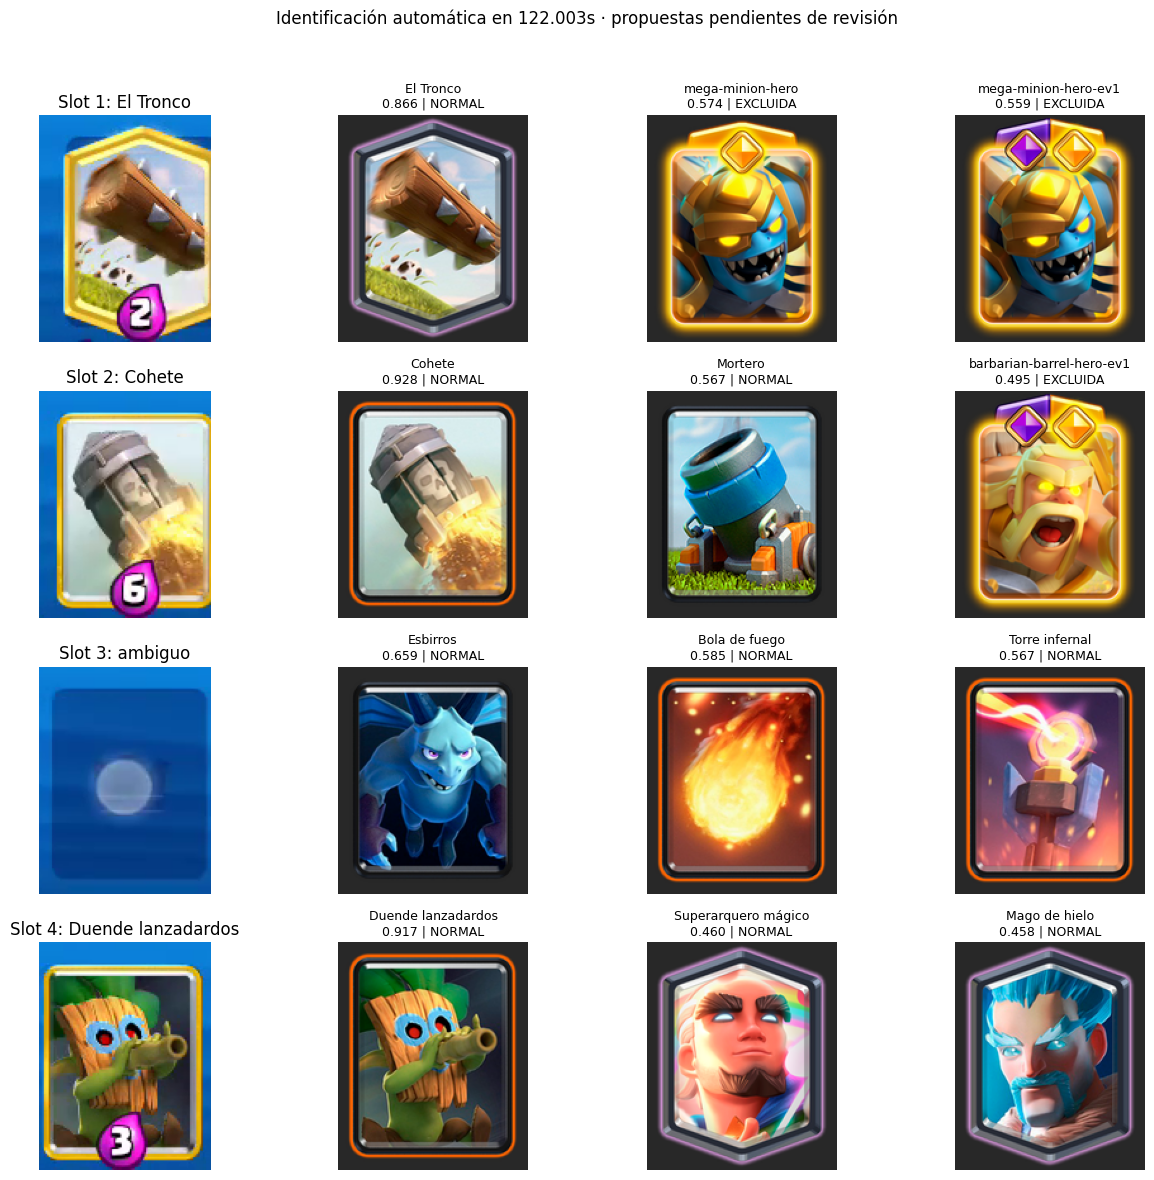

,slot,score,margin,suggested_name,suggested_key,state,name_es,card_key,cost,variant,kind,reference,cost_consistent,special_cost
0,1,0.865632,0.291974,El Tronco,the-log,propuesta,El Tronco,the-log,2.0,normal,spell,/kaggle/working/royaleapi_cache/cr-api-assets/...,NaN,False
1,2,0.927997,0.360752,Cohete,rocket,propuesta,Cohete,rocket,6.0,normal,spell,/kaggle/working/royaleapi_cache/cr-api-assets/...,NaN,False
2,3,0.658624,0.073630,Esbirros,minions,ambiguo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,0.917244,0.457635,Duende lanzadardos,dart-goblin,propuesta,Duende lanzadardos,dart-goblin,3.0,normal,troop,/kaggle/working/royaleapi_cache/cr-api-assets/...,NaN,False


In [162]:
AUTO_HAND_TIME = min(START + 8, END - 1)
fig, automatic_hand = plot_auto_hand(pipe, AUTO_HAND_TIME)
plt.show()
plt.close(fig)
display(automatic_hand)

### Propuestas de carta y ubicación en cuadrícula par ($18 \times 32$) por evento

In [164]:
AUTO_EVENT_LIMIT = 5  # None = todos los candidatos; empezar con 5 para revisar.
RUN_AUTO_EVENT_IDENTIFICATION = True

def identify_events_automatically(pipe, limit=None):
    chosen = [ev for ev in pipe.events if ev['event_type'] != 'selection_diagnostic'
              and ev['event_type'] != 'wait_candidate']
    if limit is not None:
        if int(limit) != limit or limit <= 0:
            raise ValueError('AUTO_EVENT_LIMIT debe ser un entero positivo o None.')
        chosen = chosen[:int(limit)]
    rows = []
    for number, event in enumerate(chosen, 1):
        result = pipe.identify(event)
        loc = pipe.locate(event['timestamp_sec'], result.get('kind', 'unknown'))
        top_prop = loc['proposals'][0] if loc.get('proposals') else {}
        rows.append({
            'candidate_id': event['candidate_id'], 'timestamp_sec': event['timestamp_sec'],
            'slot_candidate': event.get('slot_candidate'), 'slot_identificado': result.get('hand_slot'),
            'state': result['state'], 'card_name': result.get('name_es'),
            'variant': result.get('variant'), 'cost': result.get('cost'),
            'kind': result.get('kind'), 'score': result.get('score'),
            'cost_consistent': result.get('cost_consistent'),
            'coord_propuesta': top_prop.get('coord'),
            'tile_xy_18x32': top_prop.get('tile_xy'),
            'arena_side': top_prop.get('arena_side'),
            'zona_desambiguada': top_prop.get('zone'),
        })
        print(f'{number}/{len(chosen)} | {event["timestamp_sec"]:.3f}s | '
              f'{result["state"]} | {result.get("name_es", "sin etiqueta")} | '
              f'{top_prop.get("zone", "sin zona")}', flush=True)
    report = pd.DataFrame(rows)
    report.to_csv(pipe.root / 'automatic_cards.csv', index=False)
    return report

if RUN_AUTO_EVENT_IDENTIFICATION:
    automatic_cards = identify_events_automatically(pipe, AUTO_EVENT_LIMIT)
    display(automatic_cards)

1/5 | 120.512s | asociacion_no_resuelta | sin etiqueta | Detrás del puente derecho
2/5 | 122.103s | asociacion_no_resuelta | sin etiqueta | Detrás del puente derecho
3/5 | 123.409s | asociacion_no_resuelta | sin etiqueta | Detrás del puente derecho
4/5 | 123.610s | asociacion_no_resuelta | sin etiqueta | Detrás del puente derecho
5/5 | 134.210s | asociacion_no_resuelta | sin etiqueta | Centro izquierda del campo propio


,candidate_id,timestamp_sec,slot_candidate,slot_identificado,state,card_name,variant,cost,kind,score,cost_consistent,coord_propuesta,tile_xy_18x32,arena_side,zona_desambiguada
0,78848fab3e46b8db6491,120.512391,NaN,None,asociacion_no_resuelta,None,None,None,None,None,False,"[0.8349587801066868, 0.5839770569575679]","[15, 18]",right,Detrás del puente derecho
1,6f801644da914edbdee2,122.103148,2.0,None,asociacion_no_resuelta,None,None,None,None,None,False,"[0.8314891919048212, 0.5327233345792723]","[14, 17]",right,Detrás del puente derecho
2,e7c868a9e982dc8de191,123.409243,3.0,None,asociacion_no_resuelta,None,None,None,None,None,False,"[0.8245844037537414, 0.5817397904642959]","[14, 18]",right,Detrás del puente derecho
3,a7aae4201dc20a915bc1,123.610181,3.0,None,asociacion_no_resuelta,None,None,None,None,None,False,"[0.8298433405624064, 0.5136363967864842]","[14, 16]",right,Detrás del puente derecho
4,04dd423fbd049b830e8b,134.209645,3.0,None,asociacion_no_resuelta,None,None,None,None,None,False,"[0.4727638642116421, 0.6843512249846455]","[8, 21]",left,Centro izquierda del campo propio


## 6. Fase 3: Revisión de cada candidato y verificación de posición (Centro Izquierda / Centro Derecha)
Al desplegar una carta, el mapa tiene 18 casillas de izquierda a derecha (número par), por lo que el despliegue siempre se inclina hacia la mitad izquierda (columnas `0..8`) o hacia la mitad derecha (columnas `9..17`). Verifica en el panel que la casilla `18×32` y la zona textual (`Centro izquierda del campo propio`, `Centro derecha del campo propio`, `Detrás de la torre del rey (izquierda/derecha)`, etc.) correspondan al lado real donde cayó la tropa.

In [165]:
try:
    review_panel(pipe)
except ImportError:
    print('Instala ipywidgets y vuelve a ejecutar esta celda para abrir el panel de revisión.')

### Galería por páginas (alternativa o complemento a los botones)

In [ ]:
PAGE = 0
PAGE_SIZE = 4
INCLUDE_SELECTIONS = False
review_table = pipe.table(include_selections=INCLUDE_SELECTIONS)
if review_table.empty:
    print('No hay eventos en este filtro.')
else:
    total_pages = math.ceil(len(review_table) / PAGE_SIZE)
    if not 0 <= PAGE < total_pages:
        raise ValueError(f'PAGE debe estar entre 0 y {total_pages - 1}.')
    print('Página', PAGE, 'de', total_pages, '| candidatos', len(review_table))
    for event_id in review_table.iloc[PAGE*PAGE_SIZE:(PAGE+1)*PAGE_SIZE].candidate_id:
        fig = pipe.plot_event(event_id)
        fig.savefig(pipe.root / f'event_{event_id}.png', dpi=120, bbox_inches='tight')
        plt.show()
        plt.close(fig)

## 7. Buscar omisiones y registrar intervalos revisados

In [ ]:
try:
    audit_panel(pipe)
except ImportError:
    print('Alternativa sin botones: pipe.plot_audit(inicio, fin, step=.5)')

## 8. Generar y revisar candidatos de espera (`'esperar'`, 15%–20% del dataset)
Selecciona ventanas estables donde no ocurre ninguna jugada durante al menos $3\text{ s}$ consecutivos, sin oclusión de chat ni cambios de mano.

In [ ]:
wait_candidates = pipe.generate_waits(spacing=3.0)
print('Nuevos candidatos de espera:', len(wait_candidates))
display(wait_candidates)

In [ ]:
print('Despliegues aprobados:', len(pipe.accepted('play')))
print('Esperas aprobadas:', len(pipe.accepted('wait')))

## 9. Evaluación temporal contra anotación manual

In [ ]:
FULL_MANUAL_TRUTH = False
EVAL_START = START
EVAL_END = END
MANUAL_TRUTH_CSV = None

if not FULL_MANUAL_TRUTH:
    print('Métricas pendientes: falta confirmar anotación manual completa de la ventana.')
else:
    if not pipe.covered(EVAL_START, EVAL_END):
        raise RuntimeError('Primero registrar la auditoría completa de la ventana de evaluación.')
    if MANUAL_TRUTH_CSV:
        truth_times = pd.read_csv(MANUAL_TRUTH_CSV)['timestamp_sec'].astype(float).tolist()
    else:
        truth_times = [r['payload']['timestamp_sec'] for r in pipe.accepted('play')
                       if EVAL_START <= r['payload']['timestamp_sec'] <= EVAL_END]
    metrics = pipe.evaluate(truth_times, EVAL_START, EVAL_END, fully_annotated=True, tolerance=.3)
    display(pd.DataFrame([metrics]))

## 10. Fase 4: Exportación Local y Persistencia en Cloudflare R2
Genera los 4 fotogramas canónicos (`t-6s`, `t-4s`, `t-2s`, `t-0s`), `annotations.jsonl` con coordenadas normalizadas, casilla `tile_xy` ($18 \times 32$), lado (`left`/`right`) y zona desambiguada, y permite sincronizar atómicamente con Cloudflare R2 (`metadata/actions/<video_id>.jsonl` y `samples/`) cuando `UPLOAD_TO_R2 = True`.

In [ ]:
EXPORT_LOCAL = False   # Cambiar a True tras completar la revisión humana.
REQUIRE_BALANCE = True # True exige 15–20% de esperas; False guarda un checkpoint parcial.
UPLOAD_TO_R2 = False   # Cambiar a True en Fase 4 para subir samples/ y metadata/actions/<video_id>.jsonl a R2.

if EXPORT_LOCAL:
    export_path = pipe.export_local(balanced=REQUIRE_BALANCE)
    print('Exportación local:', export_path)
    print(validate_export(export_path))
    if UPLOAD_TO_R2:
        r2_report = sync_export_to_r2(export_path, bucket=R2_BUCKET)
        print('Sincronizado con R2:', r2_report)
else:
    print('Exportación sin ejecutar.')

## 11. Varias partidas, reanudación y balance global

In [ ]:
JOBS = []
if JOBS:
    display(process_local_jobs(JOBS, BANK_ROOT, PIPELINE_ROOT))

CHECKPOINTS = []
CONSOLIDATE_LOCAL = False
if CONSOLIDATE_LOCAL:
    if not CHECKPOINTS:
        raise ValueError('Indicar checkpoints locales aprobados.')
    combined = consolidated_local(CHECKPOINTS, PIPELINE_ROOT / 'dataset_consolidado')
    print('Consolidación local:', combined)
    print(validate_export(combined))

## Resumen de Salida JSONL
- `placement_coord`: `[x, y]` normalizado en $[0, 1]^2$.
- `tile_xy`: `[col, row]` en la cuadrícula par $18 \times 32$ (`col` $0..8$ izquierda, $9..17$ derecha).
- `arena_side`: `'left'` o `'right'` (nunca existe una casilla central exacta).
- `placement_zone`: Zona con inclinación izquierda/derecha explícita (ej. `'Centro izquierda del campo propio'`, `'Centro derecha del campo propio'`, `'Detrás de la torre del rey (izquierda)'`, `'Detrás del puente izquierdo'`).
- `canonical_zone`: Nombre de las 6 zonas preliminares del documento de especificación.
- `target_text`: Recomendación natural lista para el VLM (ej. `'Juega Valquiria en el centro izquierda del campo propio.'`).